# Further Work: Machine Learning-Based Event Selection

**Aim:** investigate whether a binary classifier improves the purity of muon-neutrino charged-current signal selection at approximately the same signal efficiency as manual cuts.

**Run order:** select the project's `.venv` Python kernel, restart the kernel, and run this notebook from top to bottom. All required functions are defined here; running `MainAnalysis_template.ipynb` first is not required.

1. Prepare the MC features, common selections, and training/validation/test split.
2. Train the Random Forest (RF), choose its threshold on validation data, and evaluate the fixed threshold on test data.
3. Compare manual and RF oscillation constraints using test MC and real data, then compare their expected sensitivity using Asimov spectra.
4. Train a small neural network (NN), choose its validation threshold, and compare all three selections on the same test data.
5. Apply the NN to MC and real data, then plot observed oscillation constraints for manual cuts, RF, and NN side by side.

Signal is `category == 21`; all other categories are background. Training and reported purity/efficiency use event weights. Classifiers use reconstructed features only; `true_E` is used later for the oscillation probability.

The original row-level split is retained. Repeated records can cross the split boundaries, so possible optimism from this overlap remains a limitation of the preliminary comparison.


## 1. Data preparation and common definitions
### 1.1 Load the cleaned MC baseline

Keep the original baseline requirement `trk_energy_tot < 1000` and the same 16 reconstructed features. Reset the row index once so the test-set indices can later retrieve the matching MC rows, including `true_E` and `weight`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Save oscillation comparison figures in one directory
output_dir = Path("output/ml_selection")
output_dir.mkdir(parents=True, exist_ok=True)

# Load the same cleaned baseline used in the main analysis
MC_ML = pd.read_pickle("data/MC_EXT_flattened.pkl")
MC_ML = MC_ML.drop("Subevent", axis=1)

MC_ML = MC_ML.loc[
    MC_ML["trk_energy_tot"] < 1000
].copy().reset_index(drop=True)

# Reconstructed features from Exercise 6
features = [
    "_closestNuCosmicDist",
    "trk_len_v",
    "trk_distance_v",
    "topological_score",
    "trk_sce_end_z_v",
    "trk_sce_end_y_v",
    "trk_sce_end_x_v",
    "trk_score_v",
    "trk_llr_pid_score_v",
    "trk_sce_start_z_v",
    "trk_sce_start_y_v",
    "trk_sce_start_x_v",
    "reco_nu_vtx_sce_x",
    "reco_nu_vtx_sce_y",
    "reco_nu_vtx_sce_z",
    "trk_energy_tot"
]

# Binary signal/background classification
X = MC_ML[features]
y = (MC_ML["category"] == 21).astype(int)
weights = MC_ML["weight"]

print("Features:", X.shape)
print("Labels:", y.shape)
print("Class counts:")
print(y.value_counts())
print("Missing feature values:", X.isna().sum().sum())


Matplotlib is building the font cache; this may take a moment.


Features: (150365, 16)
Labels: (150365,)
Class counts:
category
1    110114
0     40251
Name: count, dtype: int64
Missing feature values: 0


### 1.2 Define shared selections and weighted metrics

Every method uses the same analysis-energy requirement, $0 < E_{\mathrm{reco}} < 2\ \mathrm{GeV}$. The manual selection also applies the original vertex and topological-score cuts.

$$\mathrm{Purity} = \frac{\sum_{\text{selected signal}} w_i}{\sum_{\text{all selected}} w_i},\qquad
\mathrm{Efficiency} = \frac{\sum_{\text{selected signal}} w_i}{\sum_{\text{baseline signal}} w_i}.$$

The efficiency denominator includes all baseline signal in the dataset being evaluated, before the analysis-energy cut. Use these same functions for validation, test, and physics samples.


In [2]:
def analysis_energy_mask(frame):
    """Select reconstructed energies strictly between 0 and 2 GeV."""
    return (
        (frame["trk_energy_tot"] > 0)
        & (frame["trk_energy_tot"] < 2)
    )


def manual_selection_mask(frame):
    """Apply the original energy, vertex, and topological-score cuts."""
    return (
        analysis_energy_mask(frame)
        & frame["reco_nu_vtx_sce_x"].between(10, 245, inclusive="neither")
        & frame["reco_nu_vtx_sce_y"].between(-100, 100, inclusive="neither")
        & frame["reco_nu_vtx_sce_z"].between(20, 1000, inclusive="neither")
        & (frame["topological_score"] > 0.2)
    )


def selection_metrics(selected, labels, weights):
    """Return weighted purity and efficiency for one baseline dataset."""
    selected = np.asarray(selected, dtype=bool)
    labels = np.asarray(labels, dtype=bool)
    weights = np.asarray(weights, dtype=float)

    signal_before = weights[labels].sum()
    signal_after = weights[selected & labels].sum()
    total_after = weights[selected].sum()

    purity = signal_after / total_after if total_after > 0 else np.nan
    efficiency = signal_after / signal_before if signal_before > 0 else np.nan
    return purity, efficiency


### 1.3 Split into training, validation, and test sets

Use 60% for training, 20% for validation, and 20% for testing, with `random_state=42` and stratification by the binary label. Split features, labels, and weights together to preserve their alignment.

Choose thresholds using validation data. Apply those fixed thresholds to test data without retuning them to the test results.


In [3]:
# First split: 80% development, 20% test
X_dev, X_test, y_dev, y_test, w_dev, w_test = train_test_split(
    X, y, weights,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val, w_train, w_val = train_test_split(
    X_dev, y_dev, w_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (90219, 16)
Validation: (30073, 16)
Test: (30073, 16)


## 2. Random Forest selection
### 2.1 Train the classifier

Train the existing 300-tree RF with maximum depth 12 and at least 10 samples per leaf. Event weights enter through `sample_weight`. The output signal score will be converted into a selection using a validation threshold.


In [4]:
# Initial binary Random Forest model
rf_binary = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    criterion="gini",
    random_state=42,
    n_jobs=-1
)

rf_binary.fit(
    X_train,
    y_train,
    sample_weight=w_train
)

# Predict signal probabilities on validation data
signal_scores = rf_binary.predict_proba(X_val)[:, 1]

print("Validation scores:", signal_scores.shape)
print("Score range:", signal_scores.min(), signal_scores.max())


Validation scores: (30073,)
Score range: 0.01553488539229745 0.982185481097191


### 2.2 Measure the manual-selection reference on validation data

This provides the efficiency target for the RF and NN threshold scans. `val_energy_mask` is a Boolean array for validation rows; `analysis_energy_mask` is the reusable function that creates such masks.


In [5]:
# Establish the shared validation energy window and manual reference
val_energy_mask = analysis_energy_mask(X_val).to_numpy()
manual_selected = manual_selection_mask(X_val).to_numpy()

manual_purity, manual_efficiency = selection_metrics(
    manual_selected, y_val, w_val
)

print(f"Manual validation purity: {manual_purity:.2%}")
print(f"Manual validation efficiency: {manual_efficiency:.2%}")


Manual validation purity: 85.75%
Manual validation efficiency: 73.41%


### 2.3 Choose the RF threshold using validation data

Scan thresholds from 0 to 1 and select the point whose weighted efficiency is closest to the manual reference. Save it as `rf_threshold`; all later RF selections reuse this value.

The curve shows the purity-efficiency trade-off. The marked RF point only approximately matches manual efficiency because the threshold grid is discrete.


Manual purity: 85.75%
Manual efficiency: 73.41%
RF threshold: 0.745
RF purity: 90.55%
RF efficiency: 73.27%


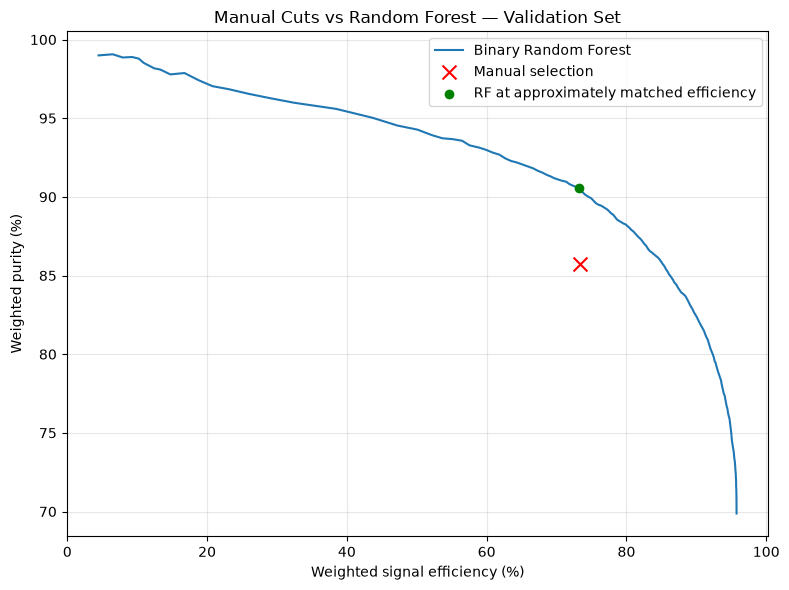

In [6]:
# Evaluate Random Forest at different score thresholds

thresholds = np.linspace(0, 1, 201)

rf_purities = []
rf_efficiencies = []

for threshold in thresholds:
    rf_selected = val_energy_mask & (signal_scores >= threshold)

    purity, efficiency = selection_metrics(
        rf_selected, y_val, w_val
    )

    rf_purities.append(purity)
    rf_efficiencies.append(efficiency)

rf_purities = np.array(rf_purities)
rf_efficiencies = np.array(rf_efficiencies)

# Find the RF threshold closest to manual efficiency
best_idx = np.argmin(np.abs(rf_efficiencies - manual_efficiency))
rf_threshold = float(thresholds[best_idx])

print(f"Manual purity: {manual_purity:.2%}")
print(f"Manual efficiency: {manual_efficiency:.2%}")
print(f"RF threshold: {rf_threshold:.3f}")
print(f"RF purity: {rf_purities[best_idx]:.2%}")
print(f"RF efficiency: {rf_efficiencies[best_idx]:.2%}")

# Plot the performance comparison
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    rf_efficiencies * 100,
    rf_purities * 100,
    label="Binary Random Forest"
)

ax.scatter(
    manual_efficiency * 100,
    manual_purity * 100,
    color="red",
    marker="x",
    s=100,
    label="Manual selection",
    zorder=5
)

ax.scatter(
    rf_efficiencies[best_idx] * 100,
    rf_purities[best_idx] * 100,
    color="green",
    marker="o",
    label="RF at approximately matched efficiency",
    zorder=5
)

ax.set_xlabel("Weighted signal efficiency (%)")
ax.set_ylabel("Weighted purity (%)")
ax.set_title("Manual Cuts vs Random Forest — Validation Set")

ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 2.4 Evaluate the fixed RF threshold on test data

Apply the validation-selected threshold to the independent test partition. Recalculate the manual reference on the same test rows. A small difference in their test efficiencies is expected; do not adjust the threshold using test data.


In [7]:
# Apply the fixed validation threshold to test scores
test_scores = rf_binary.predict_proba(X_test)[:, 1]
test_energy_mask = analysis_energy_mask(X_test).to_numpy()
manual_selected_test = manual_selection_mask(X_test).to_numpy()
rf_selected_test = test_energy_mask & (test_scores >= rf_threshold)

manual_purity_test, manual_efficiency_test = selection_metrics(
    manual_selected_test, y_test, w_test
)
rf_purity_test, rf_efficiency_test = selection_metrics(
    rf_selected_test, y_test, w_test
)

print(f"Fixed RF threshold: {rf_threshold:.3f}")
print(f"Manual test purity: {manual_purity_test:.2%}")
print(f"Manual test efficiency: {manual_efficiency_test:.2%}")
print(f"RF test purity: {rf_purity_test:.2%}")
print(f"RF test efficiency: {rf_efficiency_test:.2%}")


Fixed RF threshold: 0.745
Manual test purity: 85.97%
Manual test efficiency: 73.01%
RF test purity: 90.21%
RF test efficiency: 72.23%


### 2.5 Inspect RF feature importance

These scores describe the normalised reduction in classification impurity attributed to each feature in the fitted forest. They are not percentages of correctly classified events or the performance loss from removing a feature.


                 feature  importance
3      topological_score    0.481562
15        trk_energy_tot    0.122226
0   _closestNuCosmicDist    0.066506
8    trk_llr_pid_score_v    0.058349
5        trk_sce_end_y_v    0.048208
13     reco_nu_vtx_sce_y    0.041476
1              trk_len_v    0.031429
10     trk_sce_start_y_v    0.026128
7            trk_score_v    0.024541
2         trk_distance_v    0.022024
12     reco_nu_vtx_sce_x    0.017016
11     trk_sce_start_x_v    0.014418
4        trk_sce_end_z_v    0.013507
14     reco_nu_vtx_sce_z    0.012253
9      trk_sce_start_z_v    0.010517
6        trk_sce_end_x_v    0.009840


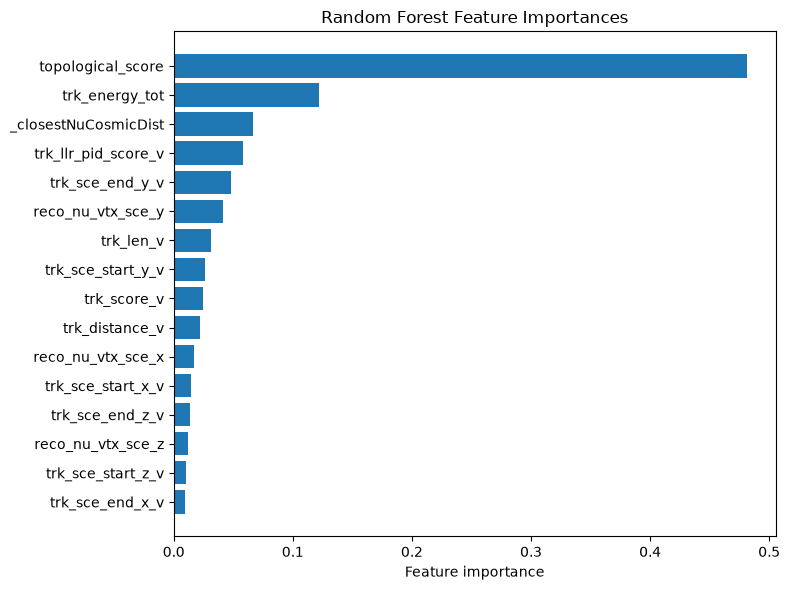

In [8]:
importance_df = pd.DataFrame({
    "feature": features,
    "importance": rf_binary.feature_importances_
}).sort_values("importance", ascending=False)

print(importance_df)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance_df["feature"], importance_df["importance"])
ax.invert_yaxis()
ax.set_xlabel("Feature importance")
ax.set_title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()


## 3. Physics validation: manual versus RF selection
### 3.1 Build selected MC and real-data samples

Use test-partition MC for both physics selections. Multiply its weights by the inverse sampling fraction (approximately 5) to estimate the expected yield for the full exposure. This rescales the expected yield; it does not restore the MC statistics lost by using only the test partition.

Apply each selection consistently to MC and the full real-data sample. This cell creates the four inputs required by the scan: `MC_manual`, `data_manual`, `MC_rf`, and `data_rf`.


In [9]:
# Retrieve test MC in exactly the same order as X_test and test_scores
MC_test_physics = MC_ML.loc[X_test.index].copy()

# Estimate the full-exposure prediction from the random test partition
mc_scale = len(MC_ML) / len(MC_test_physics)
MC_test_physics["weight"] *= mc_scale

# Prepare real data using the same baseline cleaning as MC
data_physics = pd.read_pickle("data/data_flattened.pkl")
data_physics = data_physics.drop("Subevent", axis=1)
data_physics = data_physics.loc[
    data_physics["trk_energy_tot"] < 1000
].copy()

# Apply the shared manual selection to both samples
MC_manual = MC_test_physics.loc[
    manual_selection_mask(MC_test_physics)
].copy()
data_manual = data_physics.loc[
    manual_selection_mask(data_physics)
].copy()

# Reuse the fixed validation threshold; do not tune it on real data
mc_scores = test_scores
data_scores = rf_binary.predict_proba(data_physics[features])[:, 1]

mc_rf_mask = (
    analysis_energy_mask(MC_test_physics).to_numpy()
    & (mc_scores >= rf_threshold)
)
data_rf_mask = (
    analysis_energy_mask(data_physics).to_numpy()
    & (data_scores >= rf_threshold)
)

MC_rf = MC_test_physics.loc[mc_rf_mask].copy()
data_rf = data_physics.loc[data_rf_mask].copy()

print(f"MC normalisation factor: {mc_scale:.3f}")
print(f"Fixed RF threshold: {rf_threshold:.3f}")
print(f"Manual: {len(MC_manual)} MC rows, {len(data_manual)} data events")
print(f"RF: {len(MC_rf)} MC rows, {len(data_rf)} data events")


MC normalisation factor: 5.000
Fixed RF threshold: 0.745
Manual: 18779 MC rows, 17940 data events
RF: 17937 MC rows, 16717 data events


### 3.2 Run the observed oscillation scans

Only category-21 signal undergoes disappearance. Its weight is multiplied by $1-A_{\mu\mu}\sin^2(1.27\,\Delta m^2 L/E_{\mathrm{true}})$, with $L=0.47\ \mathrm{km}$, $E_{\mathrm{true}}$ in GeV, and $\Delta m^2$ in $\mathrm{eV}^2$. Background weights are unchanged. Spectra are binned in reconstructed energy.

Keep the lab's simplified statistic:

$$\chi^2=\sum_b\frac{(P_b-O_b)^2}{(0.15P_b)^2}.$$

This treats bin uncertainties independently and includes no separate data-statistical or finite-MC statistical term. Both selections use the same binning, parameter grid, and uncertainty prescription.

Define `scan_selected_sample` once. It returns `(grid, baseline, observed)` and calculates chi-squared internally. Supplying `observed=` replaces real data with a reference spectrum for the Asimov calculation below.


In [10]:
# Common oscillation parameter space
bin_edges = np.linspace(0, 2, 21)
dm_compare = np.geomspace(0.02, 100, 121)
amplitude_compare = np.linspace(0, 1, 101)

def scan_selected_sample(mc, data, dm_values, amplitudes, observed=None):
    """Return the chi-squared grid, unoscillated prediction, and target spectrum."""
    # Unoscillated MC prediction
    baseline, _ = np.histogram(
        mc["trk_energy_tot"],
        bins=bin_edges,
        weights=mc["weight"]
    )

    # Observed data, or a supplied reference spectrum
    if observed is None:
        observed, _ = np.histogram(
            data["trk_energy_tot"], bins=bin_edges
        )
    observed = np.asarray(observed, dtype=float)

    # Only nu_mu CC signal undergoes disappearance
    signal = mc.loc[mc["category"] == 21]

    true_E = signal["true_E"].to_numpy(dtype=float)
    reco_E = signal["trk_energy_tot"].to_numpy(dtype=float)
    weights = signal["weight"].to_numpy(dtype=float)

    if not np.all(np.isfinite(true_E) & (true_E > 0)):
        raise ValueError("Signal true_E must be finite and positive.")

    grid = np.empty((len(dm_values), len(amplitudes)))

    for i, dm in enumerate(dm_values):
        phase = 1.27 * dm * 0.47 / true_E

        # Signal yield lost through oscillation in each reco-energy bin
        deficit, _ = np.histogram(
            reco_E,
            bins=bin_edges,
            weights=weights * np.sin(phase)**2
        )

        # Predictions for every amplitude at this delta_m2
        prediction = (
            baseline[None, :]
            - amplitudes[:, None] * deficit[None, :]
        )

        # Labbook's 15% systematic uncertainty approximation
        uncertainty = 0.15 * prediction
        difference = prediction - observed[None, :]

        residuals = np.divide(
            difference,
            uncertainty,
            out=np.zeros_like(prediction),
            where=uncertainty > 0
        )

        values = np.sum(residuals**2, axis=1)

        # Handle bins with zero or invalid predicted uncertainty
        invalid = (
            (uncertainty <= 0)
            & (np.abs(difference) > 1e-9)
        )
        values[np.any(invalid, axis=1)] = np.inf

        grid[i, :] = values

    return grid, baseline, observed


# Run the same analysis for both selections
samples = {
    "Manual": (MC_manual, data_manual),
    "Random Forest": (MC_rf, data_rf)
}

results = {}

for name, (mc, data) in samples.items():
    grid, baseline, observed = scan_selected_sample(
        mc, data, dm_compare, amplitude_compare
    )

    chi2_min = np.min(grid)
    i_best, j_best = np.unravel_index(
        np.argmin(grid), grid.shape
    )

    results[name] = {
        "grid": grid,
        "delta": grid - chi2_min,
        "baseline": baseline,
        "observed": observed
    }

    print(f"\n{name} selection:")
    print(f"Minimum chi2: {chi2_min:.4f}")
    if amplitude_compare[j_best] == 0:
        print("Best delta_m2: unconstrained at zero amplitude")
    else:
        print(f"Best delta_m2 grid point: {dm_compare[i_best]:.4f}")
    print(f"Best amplitude: {amplitude_compare[j_best]:.4f}")
    print(f"No-oscillation chi2: {grid[0, 0]:.4f}")
    print(
        "No-oscillation consistency:",
        np.allclose(grid[:, 0], grid[0, 0])
    )



Manual selection:
Minimum chi2: 19.5122
Best delta_m2: unconstrained at zero amplitude
Best amplitude: 0.0000
No-oscillation chi2: 19.5122
No-oscillation consistency: True



Random Forest selection:
Minimum chi2: 25.4236
Best delta_m2 grid point: 4.4026
Best amplitude: 0.0400
No-oscillation chi2: 25.8901
No-oscillation consistency: True


### 3.3 Plot the observed constraints alongside LSND and MiniBooNE

Reuse the observed scans; this cell only converts the horizontal axis and plots the two panels. Use the small-mixing branch with fixed $A_{ee}=0.24$:

$$A_{\mu e}=\left(1-\sqrt{1-A_{\mu\mu}}\right)\left(1-\sqrt{1-A_{ee}}\right).$$

Subtract each selection's own minimum chi-squared. The contour levels 4.605, 5.991, and 9.210 are the nominal two-parameter 90%, 95%, and 99% thresholds used here. Their exact coverage is not calibrated in this simplified analysis. An observed contour also depends on data-model agreement, so use the next section for an expected-sensitivity comparison.


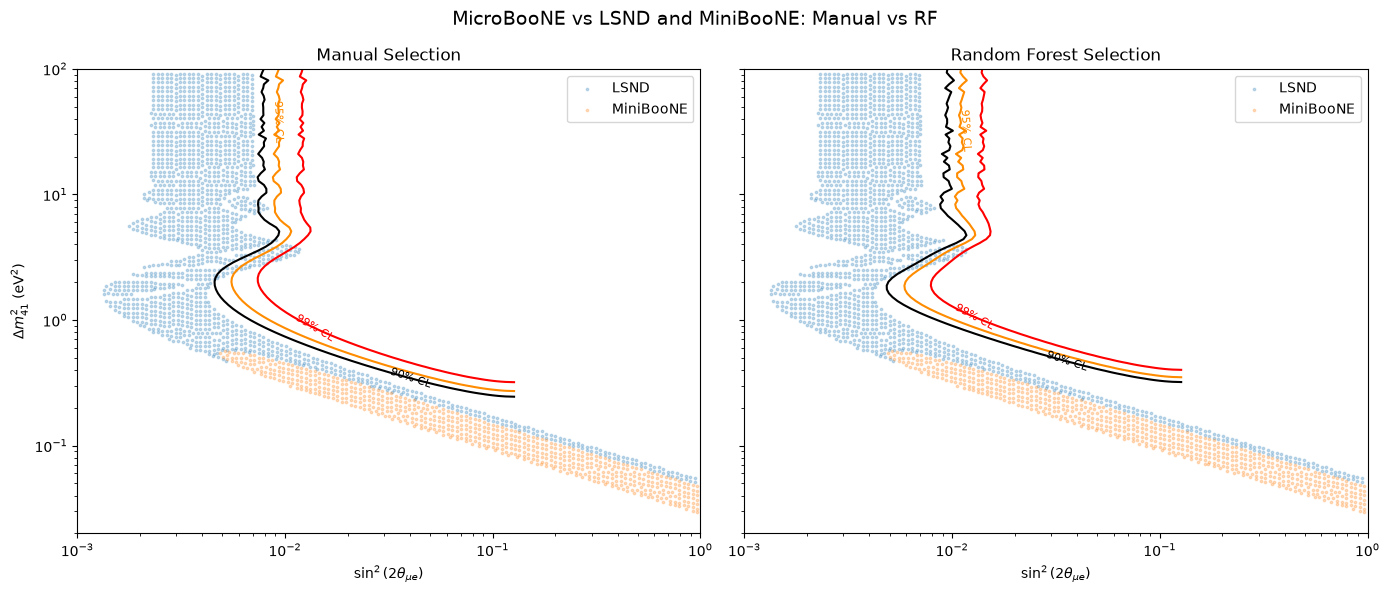

In [11]:
# Convert muon disappearance to muon-electron appearance
def appearance_amplitude(A_mumu, A_ee=0.24):
    return (
        (1 - np.sqrt(1 - A_mumu))
        * (1 - np.sqrt(1 - A_ee))
    )

appearance_values = appearance_amplitude(amplitude_compare)

# Exclude zero from the logarithmic x-axis
positive = appearance_values > 0

# Nominal confidence levels for two fitted parameters
cl_levels = [4.605, 5.991, 9.210]
cl_labels = {
    4.605: "90% CL",
    5.991: "95% CL",
    9.210: "99% CL"
}

# Load LSND and MiniBooNE reference regions
LSND_data = pd.read_csv(
    "data/DataSet_LSND.csv"
).to_numpy()

MiniBooNE_data = pd.read_csv(
    "data/DataSet_MiniBooNE.csv"
).to_numpy()

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    sharex=True, sharey=True
)

for ax, (name, result) in zip(axes, results.items()):

    ax.scatter(
        LSND_data[:, 0], LSND_data[:, 1],
        s=3, alpha=0.25, label="LSND"
    )

    ax.scatter(
        MiniBooNE_data[:, 0], MiniBooNE_data[:, 1],
        s=3, alpha=0.25, label="MiniBooNE"
    )

    # Set logarithmic axes before placing contour labels
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-3, 1)
    ax.set_ylim(0.02, 100)

    contours = ax.contour(
        appearance_values[positive],
        dm_compare,
        result["delta"][:, positive],
        levels=cl_levels,
        colors=["black", "darkorange", "red"],
        linewidths=1.5
    )

    ax.clabel(
        contours,
        fmt=cl_labels,
        fontsize=8,
        inline=False
    )

    ax.set_xlabel(r"$\sin^2(2\theta_{\mu e})$")
    ax.set_title(f"{name} Selection")
    ax.legend(loc="upper right")

axes[0].set_ylabel(r"$\Delta m_{41}^2$ (eV$^2$)")

fig.suptitle(
    "MicroBooNE vs LSND and MiniBooNE: Manual vs RF",
    fontsize=14
)

plt.tight_layout()

# Save the final comparison
fig.savefig(
    output_dir / "observed_ex14_manual_vs_rf.png",
    dpi=200, bbox_inches="tight"
)

plt.show()


### 3.4 Compare expected sensitivity with no-oscillation Asimov spectra

For each selection, use its own unoscillated MC prediction as the reference spectrum, with no random fluctuations. This asks how strongly that selection could constrain disappearance if data matched its baseline prediction, under the same 15% uncertainty approximation.

Both minimum chi-squared values should be zero. At a fixed mass splitting, a smaller appearance-amplitude limit means a stronger expected constraint.


Manual Asimov minimum chi2: 0.000000
Random Forest Asimov minimum chi2: 0.000000


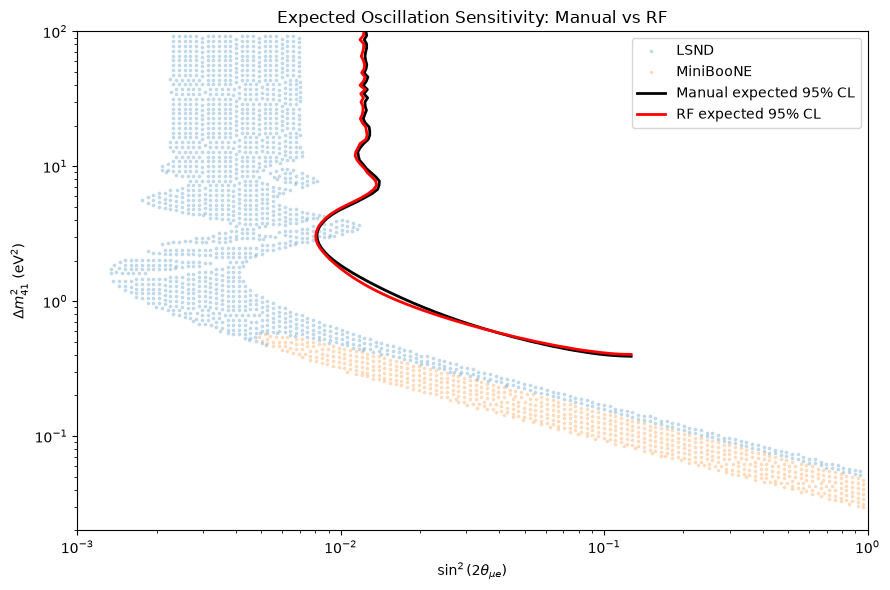

In [12]:
# Expected sensitivity using no-oscillation Asimov spectra
asimov_results = {}

for name, (mc, data) in samples.items():
    # Use each selection's unoscillated MC prediction
    asimov_target = results[name]["baseline"]

    grid, _, _ = scan_selected_sample(
        mc,
        data,
        dm_compare,
        amplitude_compare,
        observed=asimov_target
    )

    asimov_results[name] = grid - np.min(grid)

    print(
        f"{name} Asimov minimum chi2:",
        f"{np.min(grid):.6f}"
    )


# Compare expected 95% CL contours
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    LSND_data[:, 0], LSND_data[:, 1],
    s=3, alpha=0.2, label="LSND"
)

ax.scatter(
    MiniBooNE_data[:, 0], MiniBooNE_data[:, 1],
    s=3, alpha=0.2, label="MiniBooNE"
)

for name, color in [
    ("Manual", "black"),
    ("Random Forest", "red")
]:
    ax.contour(
        appearance_values[positive],
        dm_compare,
        asimov_results[name][:, positive],
        levels=[5.991],
        colors=[color],
        linewidths=2
    )

from matplotlib.lines import Line2D

handles, labels = ax.get_legend_handles_labels()

handles.extend([
    Line2D([0], [0], color="black", lw=2),
    Line2D([0], [0], color="red", lw=2)
])
labels.extend([
    "Manual expected 95% CL",
    "RF expected 95% CL"
])

ax.legend(handles, labels)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-3, 1)
ax.set_ylim(0.02, 100)

ax.set_xlabel(r"$\sin^2(2\theta_{\mu e})$")
ax.set_ylabel(r"$\Delta m_{41}^2$ (eV$^2$)")
ax.set_title("Expected Oscillation Sensitivity: Manual vs RF")

plt.tight_layout()

fig.savefig(
    output_dir / "expected_95cl_manual_vs_rf.png",
    dpi=200, bbox_inches="tight"
)

plt.show()


### 3.5 Quantify the expected 95% limits

For each requested mass splitting, use the nearest scanned mass and interpolate the first crossing of the 95% threshold along the amplitude axis. Print the actual scanned mass as well as the requested value. `RF / Manual < 1` indicates a stronger RF limit; `NaN` means the scan did not reach the threshold.


In [13]:
# Quantify expected 95% CL limits at selected mass splittings

def expected_limit(dm_target, method, level=5.991):
    # Find the nearest scanned mass splitting
    i = np.argmin(np.abs(dm_compare - dm_target))

    delta_chi2 = asimov_results[method][i]

    # Find the first crossing of the confidence threshold
    crossings = np.where(delta_chi2 >= level)[0]

    if len(crossings) == 0:
        return np.nan

    j = crossings[0]

    if j == 0:
        return appearance_values[0]

    return np.interp(
        level,
        delta_chi2[j-1:j+1],
        appearance_values[j-1:j+1]
    )


print("Target dm2 | Scanned dm2 | Manual limit | RF limit | RF / Manual")

for dm in [0.5, 1, 3, 10, 30]:
    scanned_dm = dm_compare[np.argmin(np.abs(dm_compare - dm))]
    manual = expected_limit(dm, "Manual")
    rf = expected_limit(dm, "Random Forest")

    print(
        f"{dm:10.1f} | "
        f"{scanned_dm:11.4f} | "
        f"{manual:12.5f} | "
        f"{rf:8.5f} | "
        f"{rf/manual:11.3f}"
    )


Target dm2 | Scanned dm2 | Manual limit | RF limit | RF / Manual
       0.5 |      0.4877 |      0.05670 |  0.05940 |       1.048
       1.0 |      0.9917 |      0.01835 |  0.01683 |       0.917
       3.0 |      3.0874 |      0.00812 |  0.00805 |       0.990
      10.0 |     10.3183 |      0.01217 |  0.01189 |       0.977
      30.0 |     29.9212 |      0.01236 |  0.01194 |       0.966


## 4. Neural network extension
### 4.1 Standardise inputs and train the network

Use the same features and data split as RF. Fit the scaler only on training features, then apply it to validation features. Divide both training and validation weights by the training mean weight; this preserves their relative weighting.

The network has two hidden layers (32 and 16 units) and one sigmoid output. Train for at most 60 epochs with weighted binary cross-entropy. Early stopping monitors validation loss and restores the best weights. This section trains the NN; its selection threshold is chosen in the next section.


In [14]:
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

# Start a fresh model when this cell is rerun
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Standardise inputs using training data only
scaler_nn = StandardScaler()

X_train_nn = scaler_nn.fit_transform(X_train).astype("float32")
X_val_nn = scaler_nn.transform(X_val).astype("float32")

y_train_nn = y_train.to_numpy(dtype="float32")
y_val_nn = y_val.to_numpy(dtype="float32")

# Normalise event weights for stable training
weight_scale = w_train.mean()

w_train_nn = w_train.to_numpy(dtype="float32") / weight_scale
w_val_nn = w_val.to_numpy(dtype="float32") / weight_scale

# Build a small feed-forward neural network
nn_model = tf.keras.Sequential([
    tf.keras.Input(shape=(len(features),)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy"
)

# Stop training when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

history = nn_model.fit(
    X_train_nn,
    y_train_nn,
    sample_weight=w_train_nn,
    validation_data=(X_val_nn, y_val_nn, w_val_nn),
    epochs=60,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=2
)

nn_model.summary()


Epoch 1/60


353/353 - 1s - 3ms/step - loss: 0.5062 - val_loss: 0.4613


Epoch 2/60


353/353 - 0s - 626us/step - loss: 0.4552 - val_loss: 0.4492


Epoch 3/60


353/353 - 0s - 623us/step - loss: 0.4449 - val_loss: 0.4425


... (116 outputs left out)

 Total params: 3,269 (12.77 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,180 (8.52 KB)

### 4.2 Choose the NN threshold on validation data

Scan the NN signal score and match the same manual validation efficiency used for RF. Use the shared `val_energy_mask` array and report the weighted metrics. The RF and NN may have different score thresholds because their score distributions differ.

These are validation results used to select `nn_threshold`. Section 4.3 applies that fixed threshold to test data; the threshold is not retuned using test or real-data results.


In [15]:
# Build the validation mask explicitly, independent of earlier kernel state
val_energy_mask = analysis_energy_mask(X_val).to_numpy()

# Predict NN signal scores on validation data
nn_scores_val = nn_model.predict(
    X_val_nn, verbose=0
).ravel()

nn_thresholds = np.linspace(0, 1, 501)

nn_purities = []
nn_efficiencies = []

for threshold in nn_thresholds:
    selected = val_energy_mask & (nn_scores_val >= threshold)

    purity, efficiency = selection_metrics(
        selected, y_val, w_val
    )

    nn_purities.append(purity)
    nn_efficiencies.append(efficiency)

nn_purities = np.array(nn_purities)
nn_efficiencies = np.array(nn_efficiencies)

# Match the manual selection efficiency
nn_best_idx = np.argmin(
    np.abs(nn_efficiencies - manual_efficiency)
)

nn_threshold = nn_thresholds[nn_best_idx]

print(f"NN threshold: {nn_threshold:.3f}")
print(f"NN validation purity: {nn_purities[nn_best_idx]:.2%}")
print(f"NN validation efficiency: {nn_efficiencies[nn_best_idx]:.2%}")

print(f"\nRF purity (validation): {rf_purities[best_idx]:.2%}")
print(f"RF efficiency (validation): {rf_efficiencies[best_idx]:.2%}")


NN threshold: 0.744
NN validation purity: 89.56%
NN validation efficiency: 73.50%

RF purity (validation): 90.55%
RF efficiency (validation): 73.27%


### 4.3 Compare manual cuts, RF, and NN on the test set

Transform test features using the scaler fitted on training data, then predict NN signal scores. Reuse the NN threshold selected in Section 4.2 and the RF threshold from Section 2.3.

All three methods use the same test rows, event weights, energy window, and baseline-signal efficiency denominator. The thresholds approximately matched manual efficiency on validation data; their test efficiencies can differ. This table is a test evaluation, not a new threshold scan.


In [16]:
# Apply the training-fitted scaler without fitting it again
X_test_nn = scaler_nn.transform(X_test).astype("float32")
nn_scores_test = nn_model.predict(X_test_nn, verbose=0).ravel()

# Freeze both score thresholds at their validation-selected values
nn_selected_test = test_energy_mask & (nn_scores_test >= nn_threshold)

test_selections = {
    "Manual cuts": manual_selected_test,
    "Random Forest": rf_selected_test,
    "Neural Network": nn_selected_test,
}
fixed_thresholds = {
    "Manual cuts": np.nan,
    "Random Forest": rf_threshold,
    "Neural Network": nn_threshold,
}

# Recalculate all metrics on the same test sample for a direct comparison
test_rows = []
for name, selected in test_selections.items():
    purity, efficiency = selection_metrics(selected, y_test, w_test)
    test_rows.append({
        "Method": name,
        "Score threshold": fixed_thresholds[name],
        "Weighted purity (%)": 100 * purity,
        "Weighted efficiency (%)": 100 * efficiency,
    })

test_comparison = pd.DataFrame(test_rows)
print(test_comparison.to_string(
    index=False,
    na_rep="--",
    formatters={
        "Score threshold": "{:.3f}".format,
        "Weighted purity (%)": "{:.2f}".format,
        "Weighted efficiency (%)": "{:.2f}".format,
    },
))


        Method Score threshold Weighted purity (%) Weighted efficiency (%)
   Manual cuts              --               85.97                   73.01
 Random Forest           0.745               90.21                   72.23
Neural Network           0.744               89.44                   72.77


## 5. Observed oscillation comparison: manual cuts, RF, and NN
### 5.1 Prepare NN-selected samples and scan their oscillation parameters

Reuse the test MC with the exposure-normalised weights from Section 3.1. Its row order matches `X_test`, so the NN test mask selects the corresponding MC events. Apply the same trained scaler, NN model, energy window, and fixed NN threshold to real data.

Reuse `scan_selected_sample` with the existing reconstructed-energy bins and oscillation grid. As before, only category-21 signal oscillates and each predicted bin has a 15% uncertainty. The earlier manual and RF scans are reused; only the NN scan is new.


In [17]:
# The test mask and MC_test_physics share the X_test row order
MC_nn = MC_test_physics.loc[nn_selected_test].copy()

# Apply the same scaler and fixed NN threshold to real data
X_data_nn = scaler_nn.transform(data_physics[features]).astype("float32")
nn_scores_data = nn_model.predict(X_data_nn, verbose=0).ravel()
data_nn_mask = (
    analysis_energy_mask(data_physics).to_numpy()
    & (nn_scores_data >= nn_threshold)
)
data_nn = data_physics.loc[data_nn_mask].copy()

print(f"Fixed NN threshold: {nn_threshold:.3f}")
print(f"MC normalisation factor: {mc_scale:.3f}")
print(f"NN: {len(MC_nn)} MC rows, {len(data_nn)} data events")

# Scan NN with the same function and parameter grid as manual cuts and RF
nn_grid, nn_baseline, nn_observed = scan_selected_sample(
    MC_nn, data_nn, dm_compare, amplitude_compare
)
nn_chi2_min = np.min(nn_grid)
nn_i_best, nn_j_best = np.unravel_index(np.argmin(nn_grid), nn_grid.shape)

nn_result = {
    "grid": nn_grid,
    "delta": nn_grid - nn_chi2_min,
    "baseline": nn_baseline,
    "observed": nn_observed,
}

# Preserve the earlier two-method results and build a separate comparison
comparison_results = {
    "Manual cuts": results["Manual"],
    "Random Forest": results["Random Forest"],
    "Neural Network": nn_result,
}

print(f"NN minimum chi2: {nn_chi2_min:.4f}")
if amplitude_compare[nn_j_best] == 0:
    print("NN best delta_m2: unconstrained at zero amplitude")
else:
    print(f"NN best delta_m2 grid point: {dm_compare[nn_i_best]:.4f}")
print(f"NN best amplitude: {amplitude_compare[nn_j_best]:.4f}")
print(f"NN no-oscillation chi2: {nn_grid[0, 0]:.4f}")
print("NN no-oscillation consistency:", np.allclose(nn_grid[:, 0], nn_grid[0, 0]))


Fixed NN threshold: 0.744
MC normalisation factor: 5.000
NN: 18188 MC rows, 17022 data events
NN minimum chi2: 15.3754
NN best delta_m2 grid point: 4.4026
NN best amplitude: 0.0200
NN no-oscillation chi2: 15.5066
NN no-oscillation consistency: True


### 5.2 Plot all three observed constraints alongside LSND and MiniBooNE

Each panel shows the same reference regions and the nominal 90%, 95%, and 99% contours, using the appearance-amplitude conversion with fixed $A_{ee}=0.24$. Subtract each selection's own minimum chi-squared. The axes, scan range, and colour convention are identical across panels.

These are **observed constraints**: their positions depend on the agreement between each selected real-data spectrum and its MC prediction. A stronger-looking observed contour alone does not demonstrate better expected sensitivity. The purity and efficiency table above separately measures classification performance on labelled test MC.

This plotting cell reuses the three computed grids. Changing the layout or labels does not require retraining the models or repeating the scans.


Saved figure: output/ml_selection/observed_ex14_manual_vs_rf_vs_nn.png


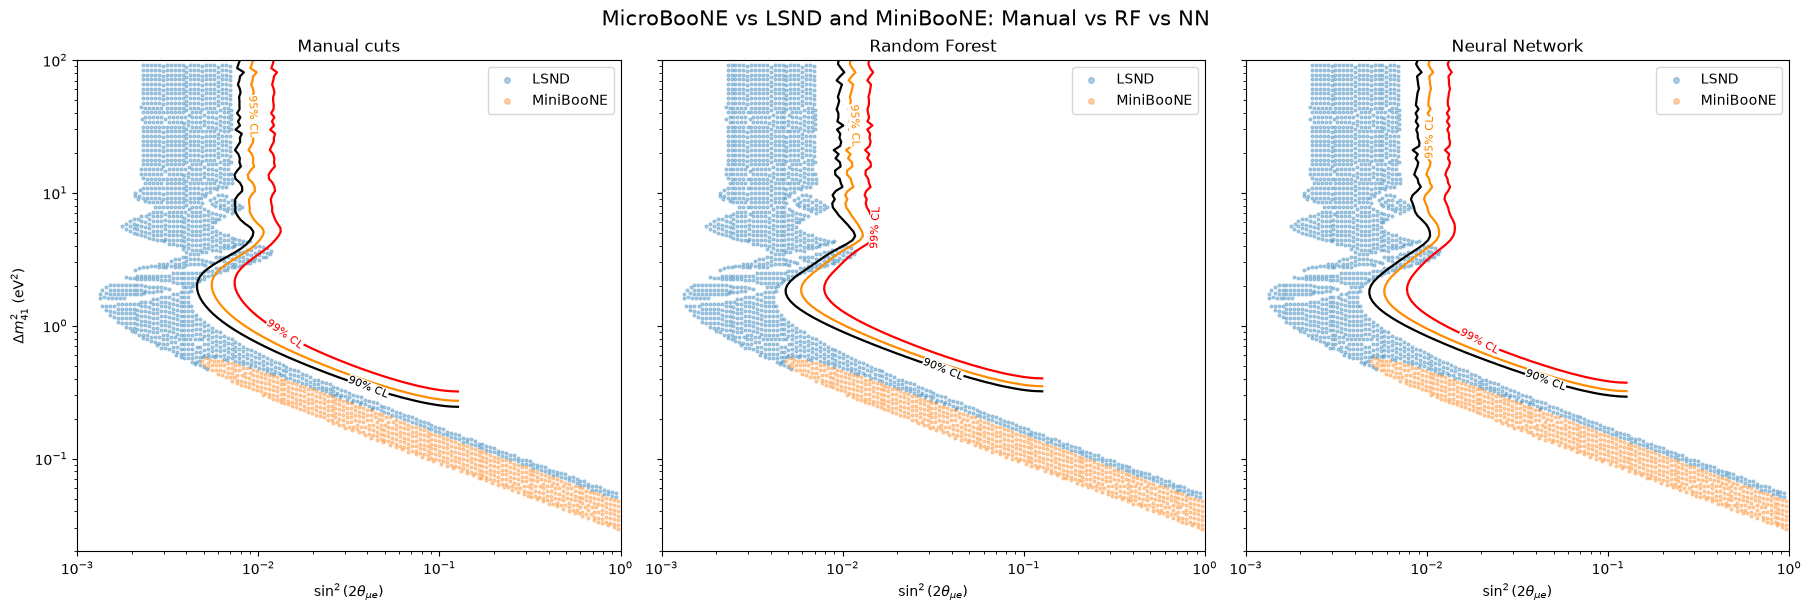

In [18]:
# Plot one panel per selection using the already computed chi-squared grids
fig, axes = plt.subplots(
    1, 3, figsize=(18, 6), sharex=True, sharey=True,
    layout="constrained",
)

for ax, (name, result) in zip(axes, comparison_results.items()):
    ax.scatter(
        LSND_data[:, 0], LSND_data[:, 1],
        s=4, alpha=0.35, color="tab:blue", label="LSND",
    )
    ax.scatter(
        MiniBooNE_data[:, 0], MiniBooNE_data[:, 1],
        s=4, alpha=0.35, color="tab:orange", label="MiniBooNE",
    )

    # Set log axes before placing contour labels
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-3, 1)
    ax.set_ylim(0.02, 100)

    contours = ax.contour(
        appearance_values[positive],
        dm_compare,
        result["delta"][:, positive],
        levels=cl_levels,
        colors=["black", "darkorange", "red"],
        linewidths=1.6,
    )
    contour_labels = ax.clabel(
        contours, fmt=cl_labels, fontsize=8, inline=False,
    )
    # Keep text readable without deleting segments of the contour paths
    for label in contour_labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 0.3})

    ax.set_title(name)
    ax.set_xlabel(r"$\sin^2(2\theta_{\mu e})$")
    ax.legend(loc="upper right", markerscale=2)

axes[0].set_ylabel(r"$\Delta m_{41}^2$ (eV$^2$)")
fig.suptitle("MicroBooNE vs LSND and MiniBooNE: Manual vs RF vs NN", fontsize=15)

comparison_plot_path = output_dir / "observed_ex14_manual_vs_rf_vs_nn.png"
fig.savefig(comparison_plot_path, dpi=200, bbox_inches="tight")
print(f"Saved figure: {comparison_plot_path}")
plt.show()


## Further Investigation: Why does improved classification not strongly improve oscillation sensitivity?

### Week 9 — Scope and fixed analysis choices

**Question:** Why does improved machine-learning-based event selection not necessarily improve oscillation sensitivity?

This investigation reuses the preceding RF and NN models, training/validation/test partitions, validation thresholds (RF **0.745**, NN **0.744**), and selected real-data samples. It does not optimise a model or threshold for the oscillation result. Run this notebook from the beginning in the existing environment; these cells reuse its variables. All new files are saved under `output/week9/`.

The comparison uses the same held-out MC partition for every method, scaled by **5** to estimate the full-exposure prediction. The common observable is `trk_energy_tot` in twenty 0.1 GeV bins from 0 to 2 GeV. Only category 21 signal is oscillated, using `true_E` and a baseline of 0.47 km. Backgrounds stay fixed. The appearance conversion remains the one defined above, with $A_{ee}=0.24$.

The observed plots use actual data. The expected-sensitivity calculations instead use the unoscillated MC prediction as a fixed **Asimov target**, separately for each selection. These answer different questions. Original sections and their saved results are retained.

In [19]:
# Freeze the existing selections and reuse the original energy binning
import hashlib
import json
from scipy.optimize import brentq

w9_dir = Path("output/week9")
for folder in ["animations", "figures", "tables"]:
    (w9_dir / folder).mkdir(parents=True, exist_ok=True)

w9_edges = np.asarray(bin_edges, dtype=float).copy()
w9_centres = 0.5 * (w9_edges[:-1] + w9_edges[1:])
w9_widths = np.diff(w9_edges)
w9_names = ["Manual", "RF", "NN"]
w9_colours = {"Manual": "#353535", "RF": "#0072B2", "NN": "#D55E00"}
w9_category_labels = {
    21: "Signal: muon CC", 7: "EXT", 4: "Mis-ID cosmic",
    5: "Outside fiducial volume", 31: "Neutral current", 10: "Electron CC",
}
w9_category_colours = {
    21: "#66A9C9", 7: "#E7AC53", 4: "#A985BE",
    5: "#83B795", 31: "#D97970", 10: "#8C8C8C",
}

assert np.allclose(w9_edges, np.linspace(0, 2, 21))
assert MC_test_physics.index.equals(X_test.index)
assert np.allclose(MC_test_physics["weight"].to_numpy(dtype=float),
                   w_test.to_numpy(dtype=float) * mc_scale)
assert np.isclose(rf_threshold, 0.745) and np.isclose(nn_threshold, 0.744)
assert [len(MC_manual), len(MC_rf), len(MC_nn)] == [18779, 17937, 18188]
assert [len(data_manual), len(data_rf), len(data_nn)] == [17940, 16717, 17022]

w9_frames = {
    "Manual": (MC_manual, data_manual),
    "RF": (MC_rf, data_rf),
    "NN": (MC_nn, data_nn),
}
w9_masks = {
    "Manual": test_selections["Manual cuts"],
    "RF": test_selections["Random Forest"],
    "NN": test_selections["Neural Network"],
}
w9_samples = {}

for name, (mc, data) in w9_frames.items():
    energy = mc["trk_energy_tot"].to_numpy(dtype=float)
    weights = mc["weight"].to_numpy(dtype=float)
    signal_mask = (mc["category"] == 21).to_numpy()
    signal_true = mc.loc[signal_mask, "true_E"].to_numpy(dtype=float)
    assert np.all(np.isfinite(weights) & (weights > 0))
    assert np.all(np.isfinite(signal_true) & (signal_true > 0))

    categories = {
        category: np.histogram(
            mc.loc[mc["category"] == category, "trk_energy_tot"],
            bins=w9_edges,
            weights=mc.loc[mc["category"] == category, "weight"],
        )[0].astype(float)
        for category in w9_category_labels
    }
    baseline = np.histogram(energy, bins=w9_edges, weights=weights)[0]
    w9_samples[name] = {
        "baseline": baseline,
        "observed": np.histogram(data["trk_energy_tot"], bins=w9_edges)[0],
        "signal": categories[21],
        "background": baseline - categories[21],
        "categories": categories,
        "mc_sumw2": np.histogram(energy, bins=w9_edges, weights=weights**2)[0],
        "signal_true_E": signal_true,
        "signal_reco_E": energy[signal_mask],
        "signal_weight": weights[signal_mask],
    }
    assert np.allclose(sum(categories.values()), baseline)


def w9_moments(sample, dm2):
    """Return the signal deficit and two moments needed for weighted MC variance."""
    phase_factor = np.sin(1.27 * dm2 * 0.47 / sample["signal_true_E"])**2
    energy = sample["signal_reco_E"]
    weights = sample["signal_weight"]
    deficit = np.histogram(energy, w9_edges, weights=weights * phase_factor)[0]
    first_w2 = np.histogram(energy, w9_edges, weights=weights**2 * phase_factor)[0]
    second_w2 = np.histogram(energy, w9_edges, weights=weights**2 * phase_factor**2)[0]
    return deficit, first_w2, second_w2


def w9_spectrum(sample, dm2, amplitude):
    """Oscillate only signal; return total yield and sum of squared event weights."""
    deficit, first_w2, second_w2 = w9_moments(sample, dm2)
    prediction = sample["baseline"] - amplitude * deficit
    mc_variance = sample["mc_sumw2"] - 2 * amplitude * first_w2 + amplitude**2 * second_w2
    # Only round-off-sized negative values are allowed before clipping
    assert np.min(prediction) > -1e-8 and np.min(mc_variance) > -1e-8
    return np.maximum(prediction, 0), np.maximum(mc_variance, 0)


def w9_contributions(prediction, target, variance):
    """Return bin contributions; keep zero-variance discrepancies as infinity."""
    residual2 = (np.asarray(prediction) - np.asarray(target))**2
    variance = np.asarray(variance)
    answer = np.divide(residual2, variance, out=np.zeros_like(residual2), where=variance > 0)
    return np.where((variance <= 0) & (residual2 > 1e-18), np.inf, answer)


def w9_variance(prediction, mc_variance, target, fraction=0.15, mode="combined"):
    """Use fixed target counts for data statistics and candidate-dependent MC/systematics."""
    systematic = (fraction * prediction)**2
    if mode == "sys_only":
        return systematic
    if mode == "combined":
        return np.asarray(target, dtype=float) + mc_variance + systematic
    raise ValueError("mode must be 'sys_only' or 'combined'")


def w9_ratio(numerator, denominator):
    """Show undefined ratios as NaN, including empty energy bins."""
    return np.divide(numerator, denominator, out=np.full_like(np.asarray(numerator, dtype=float), np.nan),
                     where=np.asarray(denominator) > 0)


def w9_save_figure(figure, filename):
    figure.savefig(w9_dir / "figures" / filename, dpi=180, bbox_inches="tight")
    plt.show()


# Save the exact fixed test masks and scores used throughout this investigation
np.savez_compressed(
    w9_dir / "tables" / "fixed_selection_snapshot.npz",
    test_index=X_test.index.to_numpy(),
    manual_mask=w9_masks["Manual"], rf_mask=w9_masks["RF"], nn_mask=w9_masks["NN"],
    rf_scores=test_scores, nn_scores=nn_scores_test,
    rf_threshold=rf_threshold, nn_threshold=nn_threshold,
    reco_energy=MC_test_physics["trk_energy_tot"].to_numpy(dtype=float),
    true_energy=MC_test_physics["true_E"].to_numpy(dtype=float),
    category=MC_test_physics["category"].to_numpy(),
    weight=MC_test_physics["weight"].to_numpy(dtype=float),
)

w9_baseline_rows = []
for name, sample in w9_samples.items():
    purity, efficiency = selection_metrics(w9_masks[name], y_test, w_test)
    w9_baseline_rows.append({
        "selection": name, "purity_percent": 100 * purity,
        "efficiency_percent": 100 * efficiency,
        "expected_signal": sample["signal"].sum(),
        "expected_background": sample["background"].sum(),
        "data_events": int(sample["observed"].sum()),
    })
w9_baseline_table = pd.DataFrame(w9_baseline_rows)
w9_baseline_table.to_csv(w9_dir / "tables" / "baseline_comparison.csv", index=False)
print(w9_baseline_table.round(3).to_string(index=False))
print(f"Frozen thresholds: RF={rf_threshold:.3f}, NN={nn_threshold:.3f}; MC scale={mc_scale:.1f}")

selection  purity_percent  efficiency_percent  expected_signal  expected_background  data_events
   Manual          85.967              73.015        14499.405             2366.900        17940
       RF          90.213              72.225        14342.693             1555.956        16717
       NN          89.438              72.773        14451.357             1706.656        17022
Frozen thresholds: RF=0.745, NN=0.744; MC scale=5.0


### 6. Oscillation histogram animations

Write $A=\sin^2(2\theta_{\mu\mu})$ and $q_i=\sin^2(1.27\,\Delta m^2\,0.47/E_{i,\mathrm{true}})$. A signal event receives weight $w_i(1-Aq_i)$; a background event keeps $w_i$. Histograms are then filled using reconstructed energy.

The first animation fixes $A=0.12$ and scans $\Delta m^2=0.1$–15 eV$^2$, including exactly 1, 3, and 10 eV$^2$. The second fixes $\Delta m^2=3$ eV$^2$ and scans $A=0$–0.30. The reference $(3,0.12)$ is near the nominal expected contour in the existing model. These sweeps illustrate response rather than retune the selection.

All panels and frames share the binning, count scale, and fractional-deficit scale. The band is 15% of the **oscillated** prediction. Displayed observed and Asimov $\chi^2$ values retain the original systematic-only statistic; the data error bars show $\sqrt{N}$ for context and are not included until Section 8. The lower panels reveal small spectral changes that are difficult to see on the count scale.

In [20]:
# Visualise spectra using the fixed selections and the existing oscillation model.
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

w9_animation_dir = w9_dir / "animations"
w9_figure_dir = w9_dir / "figures"
w9_animation_dir.mkdir(parents=True, exist_ok=True)
w9_figure_dir.mkdir(parents=True, exist_ok=True)

# Use one count scale for every selection and both parameter scans.
w9_count_max = max(
    max(1.15 * sample["baseline"].max(),
        (sample["observed"] + np.sqrt(sample["observed"])).max())
    for sample in w9_samples.values()
)
w9_count_max = 250 * np.ceil(1.12 * w9_count_max / 250)
w9_plot_names = {"Manual": "Manual cuts", "RF": "Random Forest", "NN": "Neural Network"}


def w9_make_spectrum_animation(parameters, filename, snapshot_frames):
    """Save a three-selection GIF and selected static frames without changing fits."""
    fig, axes = plt.subplots(
        2, 3, figsize=(15, 7), sharex=True, sharey="row",
        gridspec_kw={"height_ratios": [3.4, 1.3]},
    )
    fig.subplots_adjust(left=0.075, right=0.99, bottom=0.13, top=0.81,
                        hspace=0.12, wspace=0.10)
    fig.suptitle("Reconstructed-energy response to muon-neutrino disappearance",
                 fontsize=15, y=0.985)
    parameter_text = fig.text(0.5, 0.935, "", ha="center", fontsize=13)

    legend_handles = [
        Line2D([], [], color="0.35", ls="--", lw=1.7, label="Unoscillated MC"),
        Line2D([], [], color="#007C91", lw=2, label="Oscillated MC"),
        Line2D([], [], color="black", marker="o", ls="none", ms=4, label="Real data"),
        Patch(facecolor="#007C91", alpha=0.18, label="15% systematic band"),
    ]
    fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 0.895),
               ncol=4, frameon=False, fontsize=10)
    fig.text(
        0.5, 0.035,
        "Band and chi-squared: 15% systematic uncertainty only. "
        "Data error bars: sqrt(N), shown for context. "
        "Expected chi-squared uses the unoscillated Asimov spectrum.",
        ha="center", fontsize=9,
    )

    oscillated_lines, deficit_lines, bands, chi_texts = [], [], [], []
    for column, (name, sample) in enumerate(w9_samples.items()):
        ax, ax_deficit = axes[:, column]
        baseline = sample["baseline"]
        observed = sample["observed"]
        ax.stairs(baseline, w9_edges, color="0.35", ls="--", lw=1.7, zorder=3)
        line = ax.stairs(baseline, w9_edges, color="#007C91", lw=2, zorder=4)
        ax.errorbar(w9_centres, observed, yerr=np.sqrt(observed),
                    fmt="o", color="black", ms=3, elinewidth=0.8, zorder=5)
        band = ax.fill_between(
            w9_edges, np.r_[0.85 * baseline, 0.85 * baseline[-1]],
            np.r_[1.15 * baseline, 1.15 * baseline[-1]],
            step="post", color="#007C91", alpha=0.18, linewidth=0,
        )
        ax.set_title(w9_plot_names[name], fontsize=12)
        ax.set_ylim(0, w9_count_max)
        ax.grid(axis="y", alpha=0.15)
        chi_text = ax.text(
            0.97, 0.96, "", transform=ax.transAxes, ha="right", va="top",
            fontsize=10, bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
        )
        deficit_line = ax_deficit.stairs(np.zeros_like(baseline), w9_edges, baseline=None,
                                         color="#007C91", lw=2)
        ax_deficit.set_ylim(0, 32)
        ax_deficit.set_yticks([0, 10, 20, 30])
        ax_deficit.set_xlim(w9_edges[0], w9_edges[-1])
        ax_deficit.set_xlabel("Reconstructed energy (GeV)")
        ax_deficit.grid(alpha=0.15)
        oscillated_lines.append(line)
        deficit_lines.append(deficit_line)
        bands.append(band)
        chi_texts.append(chi_text)

    axes[0, 0].set_ylabel("Events per 0.1 GeV")
    axes[1, 0].set_ylabel("Oscillation deficit (%)")

    def update(frame_index):
        dm2, amplitude = parameters[frame_index]
        parameter_text.set_text(
            rf"$\Delta m^2 = {dm2:.3g}\ \mathrm{{eV}}^2$, "
            rf"$A_{{\mu\mu}} = \sin^2(2\theta_{{\mu\mu}}) = {amplitude:.3f}$"
        )
        for column, sample in enumerate(w9_samples.values()):
            prediction, _ = w9_spectrum(sample, dm2, amplitude)
            variance = (0.15 * prediction) ** 2
            observed_chi2 = w9_contributions(prediction, sample["observed"], variance).sum()
            expected_chi2 = w9_contributions(prediction, sample["baseline"], variance).sum()
            deficit = np.divide(
                100 * (sample["baseline"] - prediction), sample["baseline"],
                out=np.full_like(prediction, np.nan), where=sample["baseline"] > 0,
            )
            oscillated_lines[column].set_data(prediction)
            deficit_lines[column].set_data(deficit)
            bands[column].remove()
            bands[column] = axes[0, column].fill_between(
                w9_edges, np.r_[0.85 * prediction, 0.85 * prediction[-1]],
                np.r_[1.15 * prediction, 1.15 * prediction[-1]],
                step="post", color="#007C91", alpha=0.18, linewidth=0,
            )
            chi_texts[column].set_text(
                rf"$\chi^2_{{\rm obs}} = {observed_chi2:.2f}$" + "\n"
                + rf"$\chi^2_{{\rm exp}} = {expected_chi2:.2f}$"
            )

    animation = FuncAnimation(fig, update, frames=len(parameters), interval=200,
                              blit=False, repeat=True)
    gif_path = w9_animation_dir / filename
    animation.save(gif_path, writer=PillowWriter(fps=5), dpi=90)
    for frame_index, snapshot_name in snapshot_frames.items():
        update(frame_index)
        fig.savefig(w9_figure_dir / snapshot_name, dpi=180, facecolor="white")
    plt.close(fig)
    print(f"Saved {gif_path} ({len(parameters)} frames at 5 fps)")
    return gif_path


# Scan phase structure near the exclusion region while fixing disappearance amplitude.
w9_mass_frames = np.unique(np.r_[np.geomspace(0.1, 15, 49), 1.0, 3.0, 10.0])
w9_mass_parameters = [(float(dm2), 0.12) for dm2 in w9_mass_frames]
w9_mass_gif = w9_make_spectrum_animation(
    w9_mass_parameters, "mass_scan_fixed_amplitude_012.gif",
    {
        int(np.flatnonzero(w9_mass_frames == 1.0)[0]): "spectrum_dm1_amplitude012.png",
        int(np.flatnonzero(w9_mass_frames == 3.0)[0]): "spectrum_dm3_amplitude012.png",
    },
)

# Scan the depth of disappearance at fixed mass splitting; include A=0 and A=0.12.
w9_amplitude_frames = np.linspace(0, 0.30, 51)
w9_amplitude_parameters = [(3.0, float(amplitude)) for amplitude in w9_amplitude_frames]
w9_amplitude_gif = w9_make_spectrum_animation(
    w9_amplitude_parameters, "amplitude_scan_fixed_dm3.gif",
    {50: "spectrum_dm3_amplitude030.png"},
)

Saved output/week9/animations/mass_scan_fixed_amplitude_012.gif (52 frames at 5 fps)


Saved output/week9/animations/amplitude_scan_fixed_dm3.gif (51 frames at 5 fps)


**Saved animations:** [Mass-splitting scan](output/week9/animations/mass_scan_fixed_amplitude_012.gif) · [Amplitude scan](output/week9/animations/amplitude_scan_fixed_dm3.gif).

**Representative frames:** [1 eV², amplitude 0.12](output/week9/figures/spectrum_dm1_amplitude012.png) · [3 eV², amplitude 0.12](output/week9/figures/spectrum_dm3_amplitude012.png) · [3 eV², amplitude 0.30](output/week9/figures/spectrum_dm3_amplitude030.png).

At fixed mass splitting, amplitude changes the depth of the deficit linearly without moving its energy structure. Changing mass splitting changes the phase pattern. True-energy averaging within reconstructed bins smears oscillations; rapid oscillations tend towards an averaged response, with finite-sample fluctuations. Therefore a higher mass splitting does not produce a monotonically larger deficit in each reconstructed bin. At $(3,0.12)$ the three selections have very similar fractional deficits across the main spectrum despite their different global purities.

### 7. Bin-by-bin information and energy acceptance

Let $T_b=S_b+B_b$ be the unoscillated prediction in reconstructed bin $b$, and $D_b=\sum_{i\in\mathrm{signal},b}w_iq_i$. The oscillated prediction is $P_b=T_b-AD_b$, so

$$\frac{T_b-P_b}{T_b}=A\,\underbrace{\frac{S_b}{T_b}}_{\text{bin purity}}\,\underbrace{\frac{\sum_i w_iq_i}{\sum_iw_i}}_{\text{signal-weighted phase response}}.$$

This separates purity from the oscillation response. A large purity gain can have little effect where the phase response is small. The two reference points, $(3\ \mathrm{eV}^2,0.12)$ and $(1\ \mathrm{eV}^2,0.25)$, test different energy patterns near the nominal sensitivity boundary. The first plot combines the category composition, bin purity, fractional deficit, and phase response.

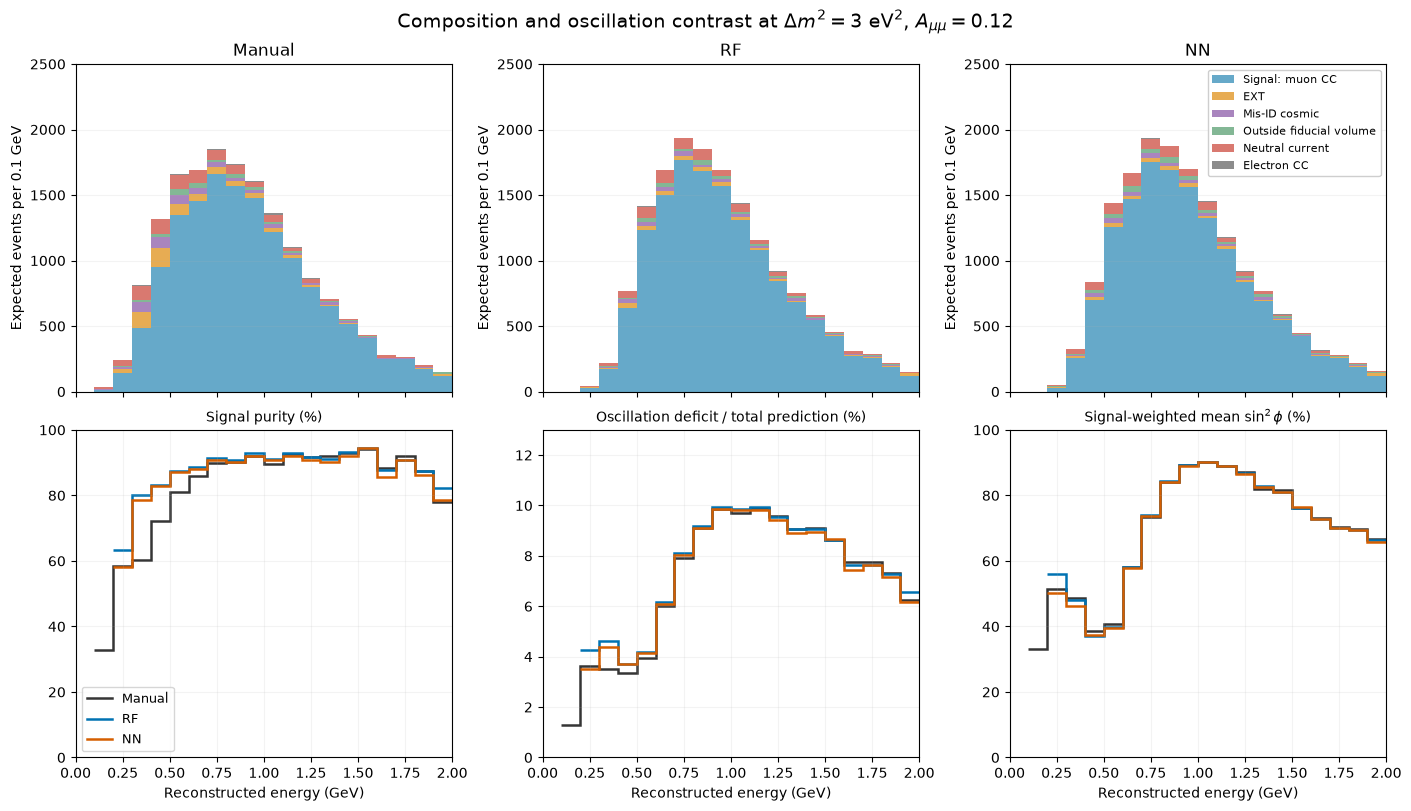

In [21]:
# Two reference points probe a near-limit response and a different phase pattern
w9_points = [(3.0, 0.12), (1.0, 0.25)]
w9_observed_results = {"Manual": results["Manual"], "RF": results["Random Forest"], "NN": nn_result}
w9_bin_rows = []

for dm2, amplitude in w9_points:
    for name, sample in w9_samples.items():
        prediction, mc_variance = w9_spectrum(sample, dm2, amplitude)
        deficit = sample["baseline"] - prediction
        q_observed = w9_contributions(prediction, sample["observed"], (0.15 * prediction)**2)
        q_expected = w9_contributions(prediction, sample["baseline"], (0.15 * prediction)**2)
        q_expected_combined = w9_contributions(prediction, sample["baseline"],
            w9_variance(prediction, mc_variance, sample["baseline"], 0.15, "combined"))

        # Decompose the actual contour statistic relative to each selection's best fit
        best_i, best_j = np.unravel_index(np.argmin(w9_observed_results[name]["grid"]),
                                        w9_observed_results[name]["grid"].shape)
        best_prediction, _ = w9_spectrum(sample, dm_compare[best_i], amplitude_compare[best_j])
        q_best = w9_contributions(best_prediction, sample["observed"], (0.15 * best_prediction)**2)

        for b, centre in enumerate(w9_centres):
            entry = {
                "selection": name, "dm2": dm2, "amplitude_mumu": amplitude,
                "energy_low": w9_edges[b], "energy_high": w9_edges[b+1],
                "signal": sample["signal"][b], "background": sample["background"][b],
                "baseline": sample["baseline"][b], "observed": sample["observed"][b],
                "prediction": prediction[b], "purity": w9_ratio(sample["signal"], sample["baseline"])[b],
                "lost_yield": deficit[b], "lost_fraction": w9_ratio(deficit, sample["baseline"])[b],
                "mean_phase_factor": w9_ratio(deficit, amplitude * sample["signal"])[b],
                "chi2_observed": q_observed[b], "delta_chi2_observed": q_observed[b] - q_best[b],
                "chi2_expected_sys": q_expected[b], "chi2_expected_combined": q_expected_combined[b],
                "mc_variance_oscillated": mc_variance[b],
            }
            entry.update({f"category_{category}": values[b] for category, values in sample["categories"].items()})
            w9_bin_rows.append(entry)
w9_bins = pd.DataFrame(w9_bin_rows)
w9_bins.to_csv(w9_dir / "tables" / "representative_bin_contributions.csv", index=False)

# Composition above; the factors governing oscillation contrast below
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, layout="constrained")
for ax, name in zip(axes[0], w9_names):
    sample = w9_samples[name]
    bottom = np.zeros_like(w9_centres)
    for category in w9_category_labels:
        values = sample["categories"][category]
        ax.bar(w9_centres, values, width=w9_widths, bottom=bottom,
               color=w9_category_colours[category], label=w9_category_labels[category], linewidth=0)
        bottom += values
    ax.set_title(name)
    ax.set_ylim(0, 2500)
    ax.set_ylabel("Expected events per 0.1 GeV")
    ax.grid(axis="y", alpha=0.15)
axes[0, 2].legend(loc="upper right", fontsize=8, framealpha=0.95)
for name in w9_names:
    rows = w9_bins.loc[(w9_bins["selection"] == name) & (w9_bins["dm2"] == 3.0)]
    for ax, variable in zip(axes[1], ["purity", "lost_fraction", "mean_phase_factor"]):
        ax.stairs(100 * rows[variable].to_numpy(), w9_edges, baseline=None,
                  color=w9_colours[name], lw=1.8, label=name)
for ax, title in zip(axes[1], ["Signal purity (%)", "Oscillation deficit / total prediction (%)", r"Signal-weighted mean $\sin^2\phi$ (%)"]):
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Reconstructed energy (GeV)")
    ax.grid(alpha=0.15)
    ax.set_xlim(0, 2)
axes[1, 0].set_ylim(0, 100)
axes[1, 1].set_ylim(0, 13)
axes[1, 2].set_ylim(0, 100)
axes[1, 0].legend(fontsize=9)
fig.suptitle(r"Composition and oscillation contrast at $\Delta m^2=3$ eV$^2$, $A_{\mu\mu}=0.12$", fontsize=14)
w9_save_figure(fig, "composition_and_oscillation_contrast.png")

#### 7.1 Check which signal and background events are exchanged

RF and NN **replace** the manual cuts; they are not extra cuts applied to the manual sample. Consequently, compare both manual-only events removed by ML and ML-only events added by it. Conditional signal efficiencies use the same unselected held-out signal denominator for every method. The true-energy panel shows 0–3 GeV; the selection itself retains the original reconstructed-energy window.

`trk_energy_tot` is an ML input and the final observable. Energy-dependent acceptance is therefore particularly relevant. This is not direct truth-label leakage, but it can reshape the selected spectrum. These plots measure that reshaping; attributing it specifically to this single input would require a separate feature-ablation study, which is outside the fixed-model comparison.

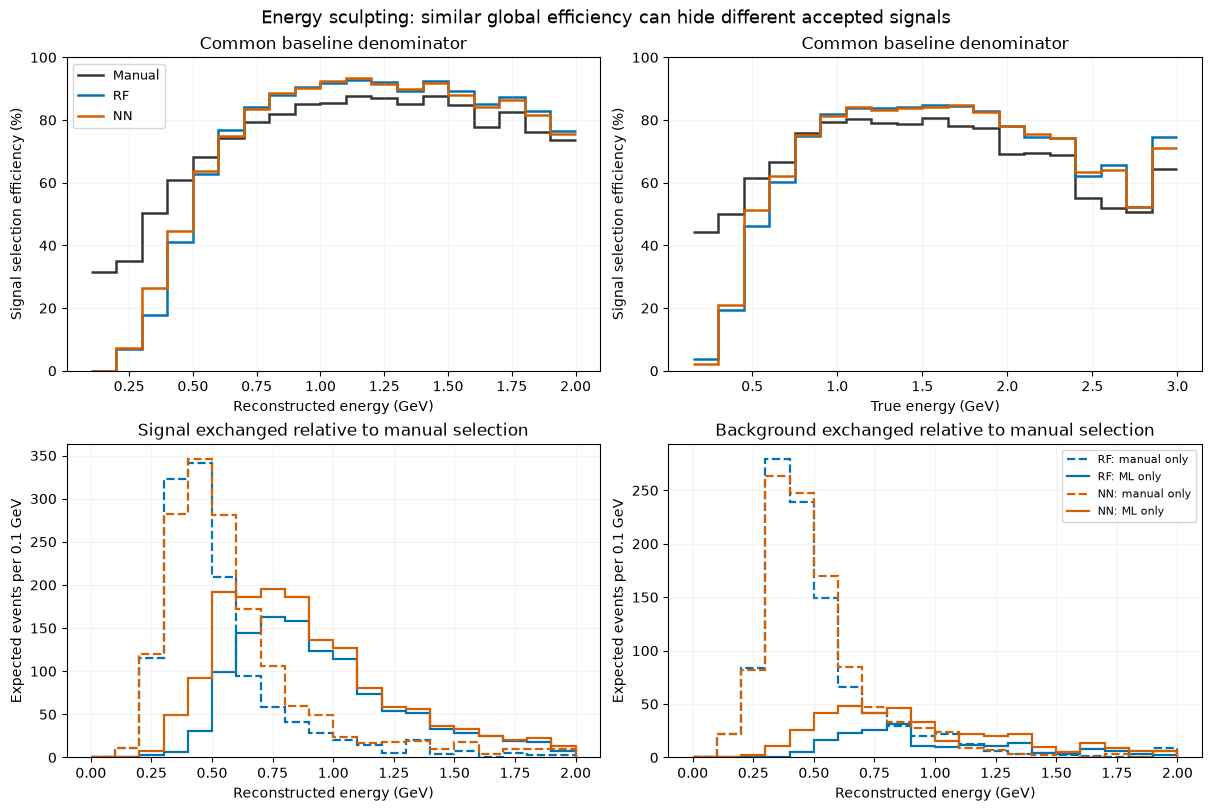

In [22]:
# Conditional signal efficiencies use the same baseline denominator for every method
w9_test_reco = MC_test_physics["trk_energy_tot"].to_numpy(dtype=float)
w9_test_true = MC_test_physics["true_E"].to_numpy(dtype=float)
w9_test_weight = MC_test_physics["weight"].to_numpy(dtype=float)
w9_test_signal = (MC_test_physics["category"] == 21).to_numpy()
w9_truth_edges = np.linspace(0, 3, 21)
w9_efficiency_rows = []
w9_exchange_rows = []
for coordinate, energies, edges in [("reconstructed", w9_test_reco, w9_edges), ("true", w9_test_true, w9_truth_edges)]:
    denominator = np.histogram(energies[w9_test_signal], edges, weights=w9_test_weight[w9_test_signal])[0]
    for name in w9_names:
        chosen = np.asarray(w9_masks[name], dtype=bool) & w9_test_signal
        numerator = np.histogram(energies[chosen], edges, weights=w9_test_weight[chosen])[0]
        for b in range(len(denominator)):
            w9_efficiency_rows.append({
                "selection": name, "coordinate": coordinate, "energy_low": edges[b], "energy_high": edges[b+1],
                "baseline_signal": denominator[b], "selected_signal": numerator[b],
                "efficiency": w9_ratio(numerator, denominator)[b],
            })

# ML selections replace the manual cuts; they can both remove and add events
for name in ["RF", "NN"]:
    manual_only = np.asarray(w9_masks["Manual"]) & ~np.asarray(w9_masks[name])
    ml_only = ~np.asarray(w9_masks["Manual"]) & np.asarray(w9_masks[name])
    for direction, mask in [("removed_from_manual", manual_only), ("added_by_ml", ml_only)]:
        signal = mask & w9_test_signal
        background = mask & ~w9_test_signal
        signal_hist = np.histogram(w9_test_reco[signal], w9_edges, weights=w9_test_weight[signal])[0]
        background_hist = np.histogram(w9_test_reco[background], w9_edges, weights=w9_test_weight[background])[0]
        phase = np.sin(1.27 * 3.0 * 0.47 / w9_test_true[signal])**2
        response_hist = np.histogram(w9_test_reco[signal], w9_edges, weights=w9_test_weight[signal] * phase)[0]
        for b in range(len(w9_centres)):
            w9_exchange_rows.append({
                "selection": name, "direction": direction,
                "energy_low": w9_edges[b], "energy_high": w9_edges[b+1],
                "signal": signal_hist[b], "background": background_hist[b],
                "oscillation_response_dm3": response_hist[b],
            })
w9_efficiencies = pd.DataFrame(w9_efficiency_rows)
w9_exchange = pd.DataFrame(w9_exchange_rows)
w9_efficiencies.to_csv(w9_dir / "tables" / "energy_dependent_efficiency.csv", index=False)
w9_exchange.to_csv(w9_dir / "tables" / "manual_only_and_ml_only_events.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for ax, coordinate, edges in zip(axes[0], ["reconstructed", "true"], [w9_edges, w9_truth_edges]):
    for name in w9_names:
        rows = w9_efficiencies.loc[(w9_efficiencies["selection"] == name) & (w9_efficiencies["coordinate"] == coordinate)]
        ax.stairs(100 * rows["efficiency"].to_numpy(), edges, baseline=None, color=w9_colours[name], label=name, lw=1.8)
    ax.set_xlabel(f"{coordinate.capitalize()} energy (GeV)")
    ax.set_ylabel("Signal selection efficiency (%)")
    ax.set_ylim(0, 100)
    ax.set_title("Common baseline denominator")
    ax.grid(alpha=0.15)
axes[0, 0].legend(fontsize=9)
for ax, component in zip(axes[1], ["signal", "background"]):
    for name in ["RF", "NN"]:
        for direction, style, label in [("removed_from_manual", "--", "manual only"), ("added_by_ml", "-", "ML only")]:
            rows = w9_exchange.loc[(w9_exchange["selection"] == name) & (w9_exchange["direction"] == direction)]
            ax.stairs(rows[component].to_numpy(), w9_edges, color=w9_colours[name], ls=style,
                      label=f"{name}: {label}", lw=1.6)
    ax.set_title(f"{component.capitalize()} exchanged relative to manual selection")
    ax.set_xlabel("Reconstructed energy (GeV)")
    ax.set_ylabel("Expected events per 0.1 GeV")
    ax.grid(alpha=0.15)
axes[1, 1].legend(fontsize=8)
fig.suptitle("Energy sculpting: similar global efficiency can hide different accepted signals", fontsize=13)
w9_save_figure(fig, "energy_acceptance_and_event_exchange.png")

#### 7.2 Separate observed mismatch from expected exclusion information

For actual data $n_b$, the raw bin contribution is $q_b=(P_b-n_b)^2/(0.15P_b)^2$. The observed contour uses $\Delta\chi^2$, not raw $\chi^2$. Its signed bin contribution is $q_b(\text{tested point})-q_b(\text{selection's global best fit})$. A negative contribution is possible and weakens exclusion of the tested point.

For the no-oscillation Asimov target $T_b$, the best fit has $A=0$ and $\chi^2=0$. The expected bin contribution is $(P_b-T_b)^2/(0.15P_b)^2$ and is nonnegative. The figure compares all three quantities. The CSV also includes expected contributions with statistical uncertainties, introduced below.

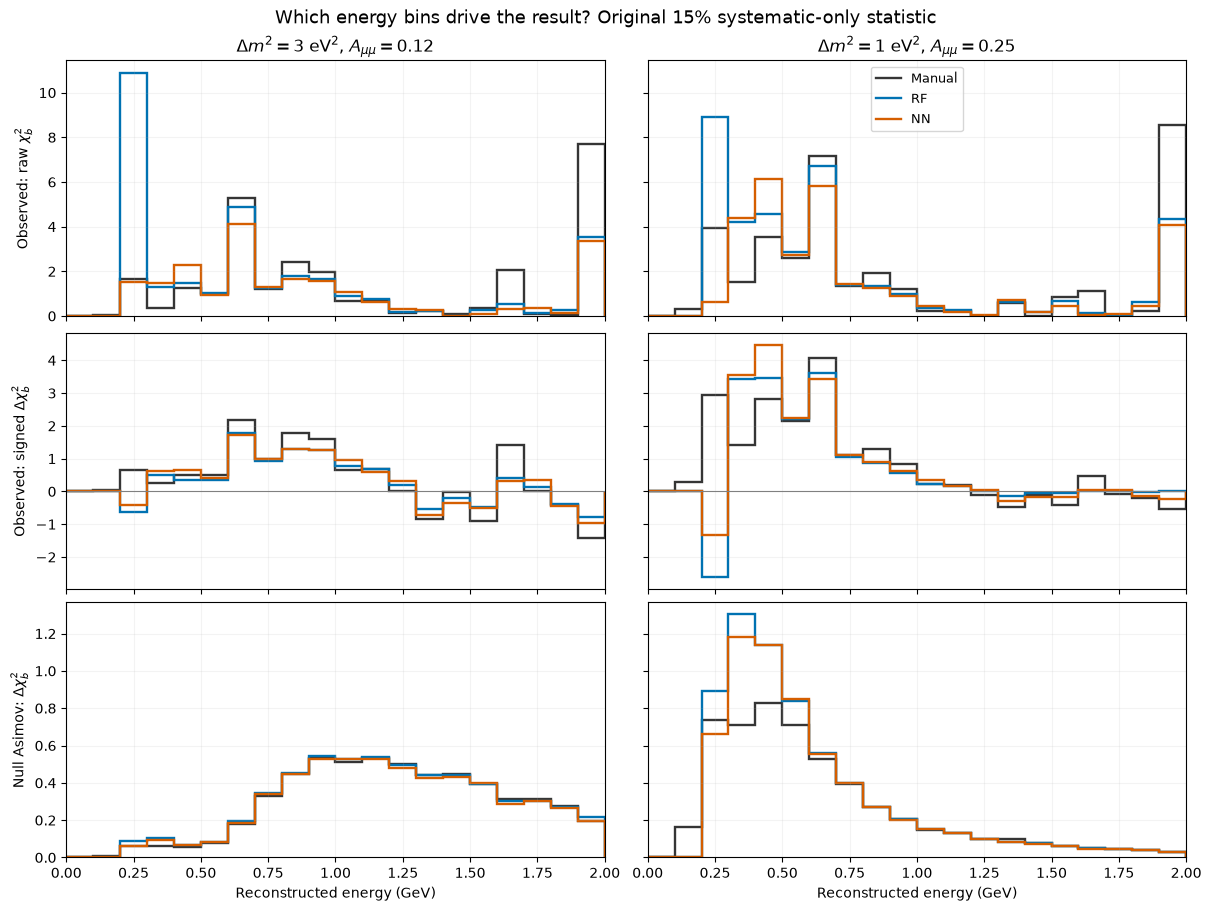

selection  energy_low  energy_high     signal  background  lost_yield  expected_sys_chi2  expected_sys_fraction  expected_combined_chi2  expected_combined_fraction
   Manual         0.0          0.5  1590.2339    808.4486     81.8702             0.1832                 0.0322                  0.1470                      0.0304
   Manual         0.5          1.2  9744.6363   1254.4074    871.3038             2.6157                 0.4597                  2.4336                      0.5025
   Manual         1.2          2.0  3164.5347    304.0438    302.5139             2.8915                 0.5081                  2.2628                      0.4672
       RF         0.0          0.5   839.7722    188.9446     40.2283             0.2573                 0.0442                  0.1526                      0.0309
       RF         0.5          1.2 10151.7982   1040.5469    916.6010             2.6905                 0.4621                  2.5098                      0.5078
       RF       

In [23]:
# Raw observed mismatch is different from the signed contribution to an exclusion contour
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True, sharey="row", layout="constrained")
for column, (dm2, amplitude) in enumerate(w9_points):
    for name in w9_names:
        rows = w9_bins.loc[(w9_bins["selection"] == name) & (w9_bins["dm2"] == dm2)]
        for row, quantity in enumerate(["chi2_observed", "delta_chi2_observed", "chi2_expected_sys"]):
            axes[row, column].stairs(rows[quantity].to_numpy(), w9_edges, color=w9_colours[name], label=name, lw=1.7)
    axes[0, column].set_title(rf"$\Delta m^2={dm2:g}$ eV$^2$, $A_{{\mu\mu}}={amplitude:.2f}$")
    axes[2, column].set_xlabel("Reconstructed energy (GeV)")
for ax in axes.flat:
    ax.grid(alpha=0.15)
    ax.set_xlim(0, 2)
axes[0, 0].set_ylabel(r"Observed: raw $\chi^2_b$")
axes[1, 0].set_ylabel(r"Observed: signed $\Delta\chi^2_b$")
axes[2, 0].set_ylabel(r"Null Asimov: $\Delta\chi^2_b$")
for ax in axes[1]: ax.axhline(0, color="0.5", lw=0.8)
axes[0, 1].legend(fontsize=9)
fig.suptitle("Which energy bins drive the result? Original 15% systematic-only statistic", fontsize=13)
w9_save_figure(fig, "observed_and_expected_bin_contributions.png")

# Compact regional accounting tests the low-information-background hypothesis
w9_region_rows = []
for name in w9_names:
    for low, high in [(0, 0.5), (0.5, 1.2), (1.2, 2.0)]:
        rows = w9_bins.loc[(w9_bins["selection"] == name) & (w9_bins["dm2"] == 3.0)
                          & (w9_bins["energy_low"] >= low - 1e-9) & (w9_bins["energy_high"] <= high + 1e-9)]
        full = w9_bins.loc[(w9_bins["selection"] == name) & (w9_bins["dm2"] == 3.0)]
        w9_region_rows.append({
            "selection": name, "energy_low": low, "energy_high": high,
            "signal": rows["signal"].sum(), "background": rows["background"].sum(),
            "lost_yield": rows["lost_yield"].sum(),
            "expected_sys_chi2": rows["chi2_expected_sys"].sum(),
            "expected_sys_fraction": rows["chi2_expected_sys"].sum() / full["chi2_expected_sys"].sum(),
            "expected_combined_chi2": rows["chi2_expected_combined"].sum(),
            "expected_combined_fraction": rows["chi2_expected_combined"].sum() / full["chi2_expected_combined"].sum(),
        })
w9_regions = pd.DataFrame(w9_region_rows)
w9_regions.to_csv(w9_dir / "tables" / "energy_region_summary.csv", index=False)
print(w9_regions.round(4).to_string(index=False))

**Bin-level findings.** At $(\Delta m^2,A)=(3,0.12)$, reconstructed energy below 0.5 GeV supplies only **3.22%** of the manual expected systematic-only $\chi^2$ (**3.04%** with the combined 15% uncertainty). Yet this region accounts for **76.39% of RF's** and **87.17% of NN's net background reduction** relative to manual cuts. Total background falls by 34.26% and 27.89%, respectively. Most of that reduction therefore occurs in a weak-information region **at this mass splitting**.

The selected signal is also redistributed. In the 0.3–0.4 GeV bin, signal efficiency is **50.36% manual, 17.81% RF, and 26.36% NN**. Above 1.2 GeV, RF/NN retain 5.90%/5.21% more signal than manual cuts, but also 7.37%/20.80% more background. Similar global efficiency does not mean the same signal-energy distribution.

This interpretation is mass dependent: at $(1,0.25)$, the region below 0.5 GeV supplies **45.69%** of manual expected systematic-only $\chi^2$. It cannot be called uninformative in general. In the observed RF sample at $(3,0.12)$, the 0.2–0.3 GeV bin contributes **10.902** to raw $\chi^2$ but **−0.638** to $\Delta\chi^2$ relative to its best fit. A conspicuous data–MC mismatch is not automatically a useful exclusion contribution.

### 8. Systematic uncertainty robustness study

We compare $f=15\%,10\%,5\%$ in two clearly separated calculations:

1. **Systematic-only control:** $V_b=(fP_b)^2$. Changing $f$ exactly rescales the whole $\chi^2$ surface by $(f_{\mathrm{old}}/f_{\mathrm{new}})^2$. Stronger contours alone do not verify a mechanism for improved ML performance.
2. **Combined variance:** $V_b=N_{b,\mathrm{target}}+V_{\mathrm{MC},b}+(fP_b)^2$. For expected sensitivity, $N_{b,\mathrm{target}}=T_b$ is the fixed unoscillated Asimov count. For an observed comparison it would be the observed count $n_b$. This is an explicit Gaussian approximation to counting statistics.

The weighted MC term uses the actual oscillated weights:

$$V_{\mathrm{MC},b}(A)=\sum_{i\in\mathrm{background},b}w_i^2+\sum_{i\in\mathrm{signal},b}w_i^2(1-Aq_i)^2.$$

Here $w_i$ already includes the factor of 5 for held-out MC normalisation, so its variance includes the factor of **25**, not 5. The unoscillated Asimov spectrum is treated as a fixed reference expectation; no second independent MC variance is added for this synthetic target. This is consistent with the weighted-histogram sum-of-squared-weights convention documented by [ROOT](https://root.cern.ch/doc/v636/classTH1.html).

For each mass on the existing 121-point grid, solve $\Delta\chi^2_{\mathrm{Asimov}}(A)=5.991$ within $0\le A\le1$. This retains the Labbook's **nominal joint two-parameter 95% contour approximation**. A one-dimensional root finder avoids the earlier 0.01 amplitude-grid rounding; it does not change the physical model or selections. No crossing is recorded as `NaN`, rather than inventing a limit at the boundary. Positive weights ensure expected $\chi^2$ increases with amplitude here. All limits use the existing appearance-amplitude conversion. A combined $f=0$ statistical-floor comparison is included in the tables.

The meaningful test of John's hypothesis is the **ML/manual expected-limit ratio** in the combined model, not just whether all curves move left as $f$ decreases. Ratios below 1 indicate stronger ML limits. Values are intersections of a nominal two-parameter contour, not separately calibrated one-parameter confidence limits.

In [24]:
# Compare nominal two-parameter 95% contour intersections at fixed mass splitting
w9_dm_values = np.asarray(dm_compare, dtype=float).copy()
w9_level = 5.991
w9_fractions = [0.15, 0.10, 0.05]
w9_settings = [(mode, f) for mode in ["sys_only", "combined"] for f in w9_fractions]
w9_settings.append(("combined", 0.0))

# Cache energy-bin moments, not retrained models or modified selections
w9_moment_grid = {
    name: [w9_moments(sample, dm2) for dm2 in w9_dm_values]
    for name, sample in w9_samples.items()
}


def w9_expected_chi2(sample, moments, amplitude, fraction, mode):
    deficit, first_w2, second_w2 = moments
    prediction = np.maximum(sample["baseline"] - amplitude * deficit, 0)
    mc_variance = np.maximum(
        sample["mc_sumw2"] - 2 * amplitude * first_w2 + amplitude**2 * second_w2, 0
    )
    variance = w9_variance(prediction, mc_variance, sample["baseline"], fraction, mode)
    return w9_contributions(prediction, sample["baseline"], variance).sum()


def w9_expected_limit(sample, moments, fraction, mode):
    """Locate a threshold crossing accurately without an amplitude-grid artefact."""
    def objective(amplitude):
        return w9_expected_chi2(sample, moments, amplitude, fraction, mode) - w9_level
    if objective(1.0) < 0:
        return np.nan
    return brentq(objective, 0.0, 1.0, xtol=1e-8)


w9_limit_rows = []
for mode, fraction in w9_settings:
    for name, sample in w9_samples.items():
        for dm2, moments in zip(w9_dm_values, w9_moment_grid[name]):
            amplitude_limit = w9_expected_limit(sample, moments, fraction, mode)
            w9_limit_rows.append({
                "selection": name, "mode": mode, "systematic_fraction": fraction,
                "dm2": dm2, "amplitude_mumu_95": amplitude_limit,
                "amplitude_mue_95": appearance_amplitude(amplitude_limit),
            })
w9_limits = pd.DataFrame(w9_limit_rows)
w9_manual_limits = w9_limits.loc[w9_limits["selection"] == "Manual", [
    "mode", "systematic_fraction", "dm2", "amplitude_mumu_95", "amplitude_mue_95"
]].rename(columns={"amplitude_mumu_95": "manual_mumu_95", "amplitude_mue_95": "manual_mue_95"})
w9_limits = w9_limits.merge(w9_manual_limits, on=["mode", "systematic_fraction", "dm2"], how="left")
w9_limits["mue_limit_ratio_to_manual"] = w9_limits["amplitude_mue_95"] / w9_limits["manual_mue_95"]
w9_limits["mumu_limit_ratio_to_manual"] = w9_limits["amplitude_mumu_95"] / w9_limits["manual_mumu_95"]
w9_limits.to_csv(w9_dir / "tables" / "expected_95_limits.csv", index=False)

# Verify the exact rescaling in the systematic-only control, including observed data
w9_rescale_errors = []
for name, sample in w9_samples.items():
    prediction, mc_variance = w9_spectrum(sample, 3.0, 0.12)
    for target in [sample["observed"], sample["baseline"]]:
        original = w9_contributions(prediction, target, (0.15 * prediction)**2).sum()
        for fraction in [0.10, 0.05]:
            rescaled = w9_contributions(prediction, target, (fraction * prediction)**2).sum()
            w9_rescale_errors.append(abs(rescaled - original * (0.15 / fraction)**2))
assert max(w9_rescale_errors) < 1e-9
print(f"Systematic-only rescaling check: maximum absolute error = {max(w9_rescale_errors):.3g}")

Systematic-only rescaling check: maximum absolute error = 5.68e-14


#### 8.1 Absolute limits, relative gains, and the variance budget

The first figure compares absolute expected contours with systematic-only and combined variances. The second plots RF/manual and NN/manual appearance-limit ratios, exposing differences hidden by overlapping contours. The third shows the systematic share of the variance in each unoscillated bin. The full tables retain both disappearance and appearance limits.

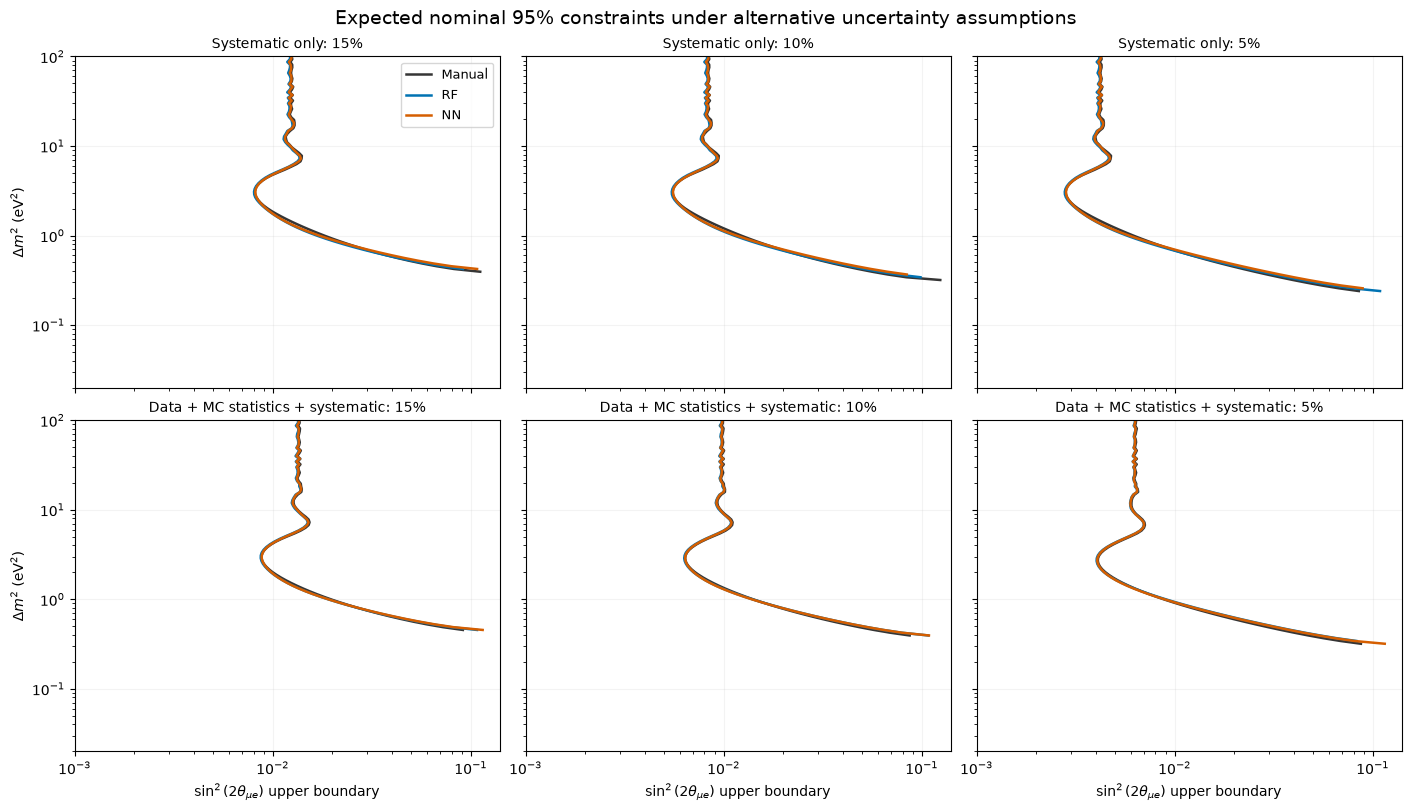

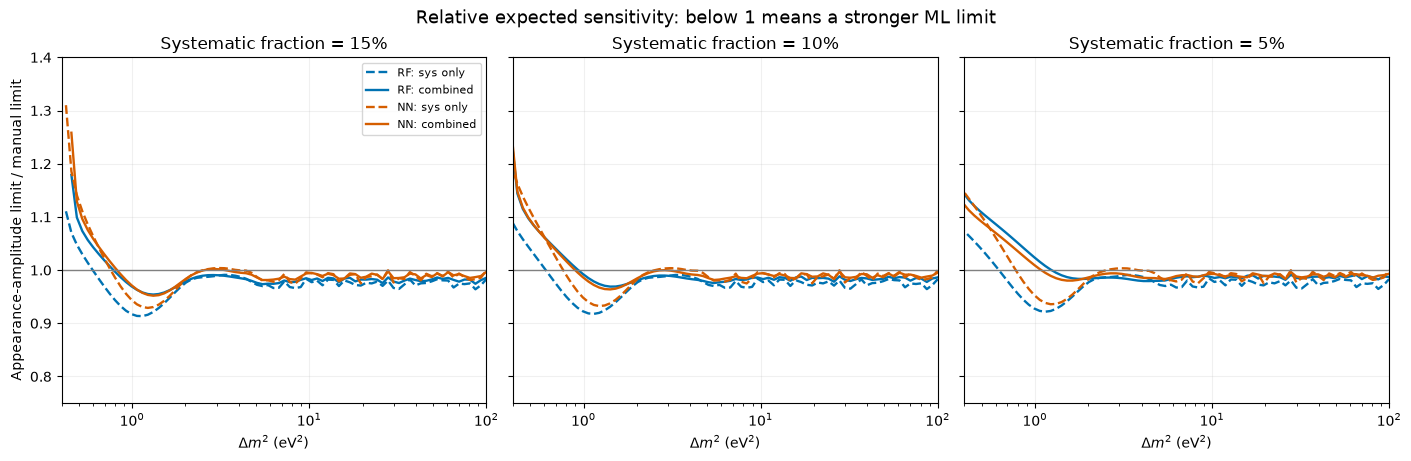

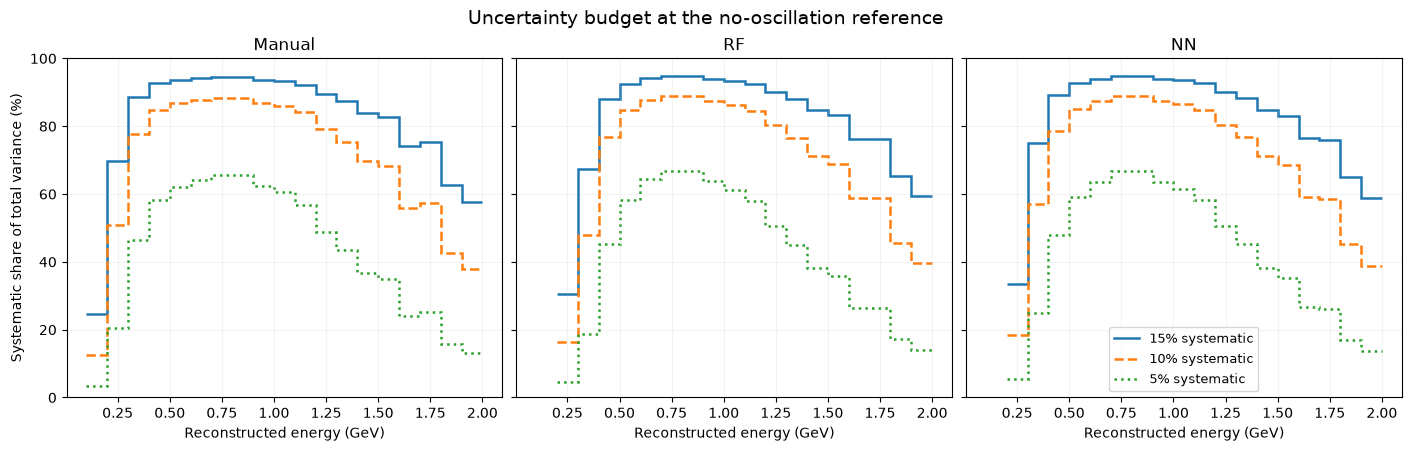

selection  systematic_fraction     dm2  amplitude_mue_95  mue_limit_ratio_to_manual
   Manual                 0.15 0.99172           0.01984                    1.00000
       RF                 0.15 0.99172           0.01924                    0.96951
       NN                 0.15 0.99172           0.01928                    0.97158
   Manual                 0.10 0.99172           0.01421                    1.00000
       RF                 0.10 0.99172           0.01411                    0.99269
       NN                 0.10 0.99172           0.01402                    0.98660
   Manual                 0.05 0.99172           0.00890                    1.00000
       RF                 0.05 0.99172           0.00911                    1.02403
       NN                 0.05 0.99172           0.00899                    1.00956
   Manual                 0.00 0.99172           0.00580                    1.00000
       RF                 0.00 0.99172           0.00607                    

In [25]:
# Absolute expected limits: changing f and adding statistics are separate comparisons
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True, layout="constrained")
for row, mode in enumerate(["sys_only", "combined"]):
    for column, fraction in enumerate(w9_fractions):
        ax = axes[row, column]
        for name in w9_names:
            curve = w9_limits.loc[(w9_limits["mode"] == mode)
                & (w9_limits["systematic_fraction"] == fraction) & (w9_limits["selection"] == name)]
            ax.plot(curve["amplitude_mue_95"], curve["dm2"], color=w9_colours[name], label=name, lw=1.8)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(1e-3, 0.14)
        ax.set_ylim(0.02, 100)
        ax.grid(alpha=0.15)
        ax.set_title(f"{'Systematic only' if mode == 'sys_only' else 'Data + MC statistics + systematic'}: {fraction:.0%}", fontsize=10)
        if row == 1: ax.set_xlabel(r"$\sin^2(2\theta_{\mu e})$ upper boundary")
        if column == 0: ax.set_ylabel(r"$\Delta m^2$ (eV$^2$)")
        if row == 0 and column == 0: ax.legend(fontsize=9)
fig.suptitle("Expected nominal 95% constraints under alternative uncertainty assumptions", fontsize=14)
w9_save_figure(fig, "uncertainty_expected_contours.png")

# Relative limits isolate whether ML benefits more as the uncertainty is reduced
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True, layout="constrained")
for ax, fraction in zip(axes, w9_fractions):
    for name in ["RF", "NN"]:
        for mode, style in [("sys_only", "--"), ("combined", "-")]:
            curve = w9_limits.loc[(w9_limits["mode"] == mode)
                & (w9_limits["systematic_fraction"] == fraction) & (w9_limits["selection"] == name)]
            ax.plot(curve["dm2"], curve["mue_limit_ratio_to_manual"], style,
                    color=w9_colours[name], lw=1.7, label=f"{name}: {'sys only' if mode == 'sys_only' else 'combined'}")
    ax.axhline(1, color="0.5", lw=1)
    ax.set_xscale("log")
    ax.set_xlim(0.4, 100)
    ax.set_ylim(0.75, 1.4)
    ax.set_title(f"Systematic fraction = {fraction:.0%}")
    ax.set_xlabel(r"$\Delta m^2$ (eV$^2$)")
    ax.grid(alpha=0.18)
axes[0].set_ylabel("Appearance-amplitude limit / manual limit")
axes[0].legend(fontsize=8)
fig.suptitle("Relative expected sensitivity: below 1 means a stronger ML limit", fontsize=13)
w9_save_figure(fig, "uncertainty_relative_ml_gain.png")

# Identify where systematic or statistical terms dominate the baseline variance
w9_variance_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True, layout="constrained")
for ax, name in zip(axes, w9_names):
    sample = w9_samples[name]
    for fraction, style in zip(w9_fractions, ["-", "--", ":"]):
        syst = (fraction * sample["baseline"])**2
        total = sample["baseline"] + sample["mc_sumw2"] + syst
        share = w9_ratio(syst, total)
        ax.stairs(100 * share, w9_edges, baseline=None, ls=style, lw=1.8, label=f"{fraction:.0%} systematic")
        for b in range(len(w9_centres)):
            w9_variance_rows.append({
                "selection": name, "systematic_fraction": fraction,
                "energy_low": w9_edges[b], "energy_high": w9_edges[b+1],
                "data_variance": sample["baseline"][b], "mc_variance": sample["mc_sumw2"][b],
                "systematic_variance": syst[b], "systematic_share": share[b],
                "effective_mc_count": w9_ratio(sample["baseline"]**2, sample["mc_sumw2"])[b],
            })
    ax.set_title(name)
    ax.set_xlabel("Reconstructed energy (GeV)")
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.15)
axes[0].set_ylabel("Systematic share of total variance (%)")
axes[-1].legend(fontsize=9)
fig.suptitle("Uncertainty budget at the no-oscillation reference", fontsize=14)
w9_save_figure(fig, "uncertainty_variance_budget.png")
w9_variance_table = pd.DataFrame(w9_variance_rows)
w9_variance_table.to_csv(w9_dir / "tables" / "bin_variance_budget.csv", index=False)

# Report a compact set of masses, including the pure statistical floor (f=0)
w9_report_masses = [w9_dm_values[np.argmin(abs(w9_dm_values - mass))] for mass in [0.5, 1, 3, 10, 30]]
w9_limit_summary = w9_limits.loc[w9_limits["dm2"].isin(w9_report_masses)].copy()
w9_limit_summary.to_csv(w9_dir / "tables" / "representative_expected_limits.csv", index=False)
print(w9_limit_summary.loc[(w9_limit_summary["mode"] == "combined")
    & (w9_limit_summary["dm2"] == w9_report_masses[1]),
    ["selection", "systematic_fraction", "dm2", "amplitude_mue_95", "mue_limit_ratio_to_manual"]
].round(5).to_string(index=False))

### 9. Numerical validation

Check the compact moment calculation against direct event-by-event reweighting for both yields and squared-weight variances. Reproduce every point of all three original observed scans and verify the signed bin sums. Check every expected contour crossing, the systematic-only rescaling identity, the ordering of absolute limits, and the saved GIF frames. Save versions and fingerprints of the unchanged test indices and selection masks in `output/week9/tables/validation.json`.

In [26]:
# Check the physics calculations against direct event-by-event reweighting
from importlib.metadata import version
from PIL import Image

w9_direct_checks = 0
for name, (mc, _) in w9_frames.items():
    sample = w9_samples[name]
    signal_mask = (mc["category"] == 21).to_numpy()
    for dm2, amplitude in [(1.0, 0.0), (1.0, 0.25), (3.0, 0.12), (10.0, 1.0)]:
        direct_weights = mc["weight"].to_numpy(dtype=float).copy()
        phase = 1.27 * dm2 * 0.47 / mc.loc[signal_mask, "true_E"].to_numpy(dtype=float)
        direct_weights[signal_mask] *= 1 - amplitude * np.sin(phase)**2
        direct_prediction = np.histogram(mc["trk_energy_tot"], w9_edges, weights=direct_weights)[0]
        direct_variance = np.histogram(mc["trk_energy_tot"], w9_edges, weights=direct_weights**2)[0]
        prediction, mc_variance = w9_spectrum(sample, dm2, amplitude)
        np.testing.assert_allclose(prediction, direct_prediction, atol=1e-8, rtol=1e-10)
        np.testing.assert_allclose(mc_variance, direct_variance, atol=1e-8, rtol=1e-10)
        w9_direct_checks += 1

    # Reproduce the complete original observed scan, including its global minimum
    for i, moments in enumerate(w9_moment_grid[name]):
        prediction = sample["baseline"][None, :] - amplitude_compare[:, None] * moments[0][None, :]
        grid_row = w9_contributions(prediction, sample["observed"], (0.15 * prediction)**2).sum(axis=1)
        np.testing.assert_allclose(grid_row, w9_observed_results[name]["grid"][i], atol=1e-8)
    for dm2, amplitude in w9_points:
        rows = w9_bins.loc[(w9_bins["selection"] == name) & (w9_bins["dm2"] == dm2)]
        expected_delta = rows["chi2_observed"].sum() - w9_observed_results[name]["grid"].min()
        np.testing.assert_allclose(rows["delta_chi2_observed"].sum(), expected_delta, atol=1e-8)

# Every finite limit must actually lie on the stated nominal contour
w9_root_errors = []
for row in w9_limits.itertuples(index=False):
    i = int(np.flatnonzero(w9_dm_values == row.dm2)[0])
    sample, moments = w9_samples[row.selection], w9_moment_grid[row.selection][i]
    if np.isfinite(row.amplitude_mumu_95):
        value = w9_expected_chi2(sample, moments, row.amplitude_mumu_95, row.systematic_fraction, row.mode)
        w9_root_errors.append(abs(value - w9_level))
    else:
        assert w9_expected_chi2(sample, moments, 1.0, row.systematic_fraction, row.mode) < w9_level
assert max(w9_root_errors) < 1e-5

# Check that smaller uncertainty never weakens an absolute expected limit
for (name, mode, dm2), rows in w9_limits.groupby(["selection", "mode", "dm2"]):
    limits = rows.sort_values("systematic_fraction")["amplitude_mumu_95"].dropna().to_numpy()
    assert np.all(np.diff(limits) >= -1e-8)

# Verify saved animations contain the requested number of distinct frames
w9_gif_checks = {}
for path, expected_frames in [(w9_mass_gif, len(w9_mass_parameters)),
                              (w9_amplitude_gif, len(w9_amplitude_parameters))]:
    with Image.open(path) as gif:
        assert gif.n_frames == expected_frames
        digests = []
        for frame in range(gif.n_frames):
            gif.seek(frame)
            digests.append(hashlib.sha256(gif.convert("RGB").tobytes()).hexdigest())
        assert len(set(digests)) == expected_frames
        w9_gif_checks[path.name] = {"frames": gif.n_frames, "size": list(gif.size)}

w9_validation = {
    "status": "passed", "direct_reweighting_checks": w9_direct_checks,
    "original_observed_grids_reproduced": list(w9_names),
    "maximum_contour_chi2_error": float(max(w9_root_errors)),
    "maximum_systematic_rescaling_error": float(max(w9_rescale_errors)),
    "mc_normalisation": float(mc_scale),
    "thresholds": {"RF": float(rf_threshold), "NN": float(nn_threshold)},
    "test_index_sha256": hashlib.sha256(X_test.index.to_numpy().tobytes()).hexdigest(),
    "test_mask_sha256": {name: hashlib.sha256(np.asarray(mask, dtype=bool).tobytes()).hexdigest()
                         for name, mask in w9_masks.items()},
    "versions": {package: version(package) for package in
                 ["numpy", "pandas", "matplotlib", "scipy", "scikit-learn", "tensorflow", "Pillow"]},
    "animations": w9_gif_checks,
}
(w9_dir / "tables" / "validation.json").write_text(json.dumps(w9_validation, indent=2))
print(f"PASS: {w9_direct_checks} direct event-weight checks, all original observed scan points, bin sums,")
print("      expected contour roots, uncertainty ordering, and both animation frame sequences.")
print(f"Maximum contour chi-squared residual: {max(w9_root_errors):.3g}")

PASS: 12 direct event-weight checks, all original observed scan points, bin sums,
      expected contour roots, uncertainty ordering, and both animation frame sequences.
Maximum contour chi-squared residual: 6.5e-07


### 10. Quantitative conclusions

The fixed held-out samples give:

| Selection | Weighted purity | Weighted efficiency | Expected signal | Expected background |
|---|---:|---:|---:|---:|
| Manual | 85.97% | 73.01% | 14,499.4 | 2,366.9 |
| RF | 90.21% | 72.23% | 14,342.7 | 1,556.0 |
| NN | 89.44% | 72.77% | 14,451.4 | 1,706.7 |

At exactly $(\Delta m^2,A)=(3,0.12)$, expected systematic-only $\Delta\chi^2$ is **5.690, 5.822, 5.647** for manual, RF, and NN. With data and weighted MC statistics included at 15%, it is **4.843, 4.942, 4.825**. Substantial purity gains therefore produce almost unchanged expected information at this point. Global efficiency has not increased: the improvement is primarily in purity.

The combined-variance expected appearance-limit ratios below quantify the effect of reducing systematics. These masses are the **nearest existing scan points**, distinct from the exact masses used for the bin plots. Lower ratios are better for ML.

| Mass splitting (eV²) | Systematic fraction | RF / manual limit | NN / manual limit |
|---|---:|---:|---:|
| 0.992 | 15% | 0.970 | 0.972 |
| 0.992 | 10% | 0.993 | 0.987 |
| 0.992 | 5% | 1.024 | 1.010 |
| 3.087 | 15% | 0.990 | 1.002 |
| 3.087 | 10% | 0.989 | 0.999 |
| 3.087 | 5% | 0.985 | 0.993 |

Near 1 eV², reducing systematics improves the **absolute manual appearance limit** from approximately **0.01984 to 0.00890**, but RF's relative advantage changes from about **3.0% stronger to 2.4% weaker**. Near 3 eV², the RF advantage instead grows modestly, from approximately **1.0% to 1.5%**. At 0.488 eV², both ML methods are weaker than manual cuts for all three fractions. The outcome depends on mass splitting and accepted energy distribution.

**What is supported:** 15% systematics dominate much of the central energy spectrum. For example, in the manual 0.7–0.8 GeV bin they supply about **94.5%** of the baseline total variance at 15%, falling to **65.7%** at 5%. Large systematics limit absolute sensitivity. However, the combined-variance comparison does **not** support the stronger claim that they universally conceal a large ML advantage. Removing low-energy background, reshaping signal acceptance, and changing the statistical weight of bins explain why classification and oscillation performance need not improve together.

With a purely fractional uncertainty, the absolute count scale cancels from each expected bin contribution: the fractional oscillation deficit is what matters. Adding data and MC statistics restores a dependence on the number and weights of retained events. A purer but sparsely populated bin can therefore become less useful. This helps explain why the relative ranking changes when statistical terms become more important.

**What remains unverified:** the causal contribution of `trk_energy_tot` as an input, the true detector/flux systematic model, the significance of few-percent method differences, and the performance on independent simulated samples. No feature ablation, threshold retuning, or new training is used to improve the result.

### Statistical and physical limitations

- The Labbook's diagonal fractional uncertainty is a teaching approximation, not a reconstructed MicroBooNE covariance matrix. Bins and uncertainty sources are treated as independent; correlated flux, detector, and cross-section effects are omitted.
- These parameter-dependent weighted chi-squared statistics are not a full profile likelihood. Sparse bins, the physical amplitude boundary, and an unidentified mass at zero amplitude mean that exact 95% coverage is not established. The [PDG Statistics review, Section 40.4.2.3](https://pdg.lbl.gov/2025/reviews/rpp2025-rev-statistics.pdf) discusses conditions behind asymptotic confidence regions. The Asimov target follows the expected-data idea of [Cowan et al.](https://arxiv.org/abs/1007.1727), but this simplified statistic has not been calibrated to median limits with pseudoexperiments.
- Squared-weight variances assume independent weighted records. The previously identified repeated-record issue and the original split are retained, as requested; record dependence can weaken the simple statistical interpretation. The three selections overlap, so their results are correlated. A few-percent difference is a deterministic model comparison, not a demonstrated statistically significant improvement.
- The 20% held-out MC prediction has larger finite-MC uncertainty than a prediction made with the full sample. Scaling restores expected yields, not the original MC statistical precision. All methods use the same held-out normalisation. This also explains why the manual result here need not exactly reproduce the core notebook's full-MC manual result.
- Only category 21 is oscillated; other neutrino backgrounds and EXT are fixed. The baseline and appearance conversion are held fixed. High-mass wiggles reflect the existing finite MC and mass grid; no smoothing is used to make the contours look stronger.

**Reproducibility:** the preceding sections define the unchanged models and selections; the new section writes 2 GIFs, 9 PNG figures, numerical CSV tables, a fixed-mask snapshot, and a validation record under `output/week9/`. All original notebook cells are retained.